<a href="https://colab.research.google.com/github/yujiunzou/supply-chain-analytics/blob/main/03_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 供應鏈訂單、產能與運費分析｜EDA

## Executive Summary 重點摘要

資料為 **2013-05-26 單日的 9,215 筆訂單**（46 位顧客、772 項產品、7 座有訂單的工廠）。主要發現：

1. **工廠高度集中且產能吃緊**：PLANT03 承擔 92.69% 訂單、產能利用率 843%，最少需 9 天處理；共 4 座工廠訂單量超過單日產能。
2. **PLANT08 配送風險最高**：延遲率 17.65%，約每 6 筆訂單就有 1 筆延遲。
3. **供應與物流集中度高**：614 項產品（占需求單位數 90.4%）僅 1 座工廠可供應；67.98% 訂單由 V444_0 承運；98.11% 訂單走 PORT04 → PORT09。
4. **VMI 配置與歷史訂單不符**：8 位 VMI 顧客占 22.67% 訂單，但與目前指定工廠符合的訂單為 0 筆（需歷史配置才能判斷是否違規）。
5. **運費僅部分可估算**：以原承運商費率可估算 75.87% 訂單（總計 69,568.23）；改用替代承運商後覆蓋率提高到 90.55%（總計 101,753.73），仍有 871 筆（9.45%）無費率，主因是 V44_3 完全沒有費率紀錄。

> 資料限制：僅單日資料、產能為目前限制、`transport_days` 為設定值而非實際送達時間。詳見第 9 章。

## 環境設定與資料載入 clone github repository

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!git clone https://github.com/yujiunzou/supply-chain-analytics.git

Cloning into 'supply-chain-analytics'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 32 (delta 8), reused 17 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 310.90 KiB | 5.87 MiB/s, done.
Resolving deltas: 100% (8/8), done.


In [ ]:
from pathlib import Path

project_root = Path("/content/supply-chain-analytics")
cleaned_dir = project_root / "data" / "cleaned"

In [ ]:
import pandas as pd
from pathlib import Path

cleaned_dir = Path(
    "/content/supply-chain-analytics/data/cleaned"
)

table_schemas = {
    "orders": {
        "order_id": "string",
        "origin_port": "string",
        "carrier": "string",
        "service_level": "string",
        "customer": "string",
        "product_id": "string",
        "plant_code": "string",
        "destination_port": "string"
    },

    "freight_rates": {
        "carrier": "string",
        "origin_port": "string",
        "destination_port": "string",
        "service_level": "string",
        "transport_mode": "string",
        "carrier_type": "string"
    },

    "plant_ports": {
        "plant_code": "string",
        "port": "string"
    },

    "products_per_plant": {
        "plant_code": "string",
        "product_id": "string"
    },

    "vmi_customers": {
        "plant_code": "string",
        "customer": "string"
    },

    "warehouse_capacities": {
        "plant_code": "string"
    },

    "warehouse_costs": {
        "plant_code": "string"
    }
}

In [ ]:
orders = pd.read_csv(
    cleaned_dir / "orders_clean.csv",
    dtype=table_schemas["orders"],
    parse_dates=["order_date"]
)

freight_rates = pd.read_csv(
    cleaned_dir / "freight_rates_clean.csv",
    dtype=table_schemas["freight_rates"]
)

plant_ports = pd.read_csv(
    cleaned_dir / "plant_ports_clean.csv",
    dtype=table_schemas["plant_ports"]
)

products_per_plant = pd.read_csv(
    cleaned_dir / "products_per_plant_clean.csv",
    dtype=table_schemas["products_per_plant"]
)

vmi_customers = pd.read_csv(
    cleaned_dir / "vmi_customers_clean.csv",
    dtype=table_schemas["vmi_customers"]
)

warehouse_capacities = pd.read_csv(
    cleaned_dir / "warehouse_capacities_clean.csv",
    dtype=table_schemas["warehouse_capacities"]
)

warehouse_costs = pd.read_csv(
    cleaned_dir / "warehouse_costs_clean.csv",
    dtype=table_schemas["warehouse_costs"]
)

In [ ]:
tables = {
    "Orders": orders,
    "Freight Rates": freight_rates,
    "Plant Ports": plant_ports,
    "Products per Plant": products_per_plant,
    "VMI Customers": vmi_customers,
    "Warehouse Capacities": warehouse_capacities,
    "Warehouse Costs": warehouse_costs
}

for name, df in tables.items():
    print(f"\n{name}")
    print(df.dtypes)


Orders
order_id                string[python]
order_date              datetime64[ns]
origin_port             string[python]
carrier                 string[python]
transport_days                   int64
service_level           string[python]
ship_ahead_day_count             int64
ship_late_day_count              int64
customer                string[python]
product_id              string[python]
plant_code              string[python]
destination_port        string[python]
unit_quantity                    int64
weight                         float64
weight_valid                      bool
dtype: object

Freight Rates
carrier             string[python]
origin_port         string[python]
destination_port    string[python]
min_weight                 float64
max_weight                 float64
service_level       string[python]
min_cost                   float64
rate                       float64
transport_mode      string[python]
transport_days               int64
carrier_type        string[p

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9215 entries, 0 to 9214
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   order_id              9215 non-null   string        
 1   order_date            9215 non-null   datetime64[ns]
 2   origin_port           9215 non-null   string        
 3   carrier               9215 non-null   string        
 4   transport_days        9215 non-null   int64         
 5   service_level         9215 non-null   string        
 6   ship_ahead_day_count  9215 non-null   int64         
 7   ship_late_day_count   9215 non-null   int64         
 8   customer              9215 non-null   string        
 9   product_id            9215 non-null   string        
 10  plant_code            9215 non-null   string        
 11  destination_port      9215 non-null   string        
 12  unit_quantity         9215 non-null   int64         
 13  weight            

#  探索性資料分析 (EDA)

In [ ]:
orders.head()

,order_id,order_date,origin_port,carrier,transport_days,service_level,ship_ahead_day_count,ship_late_day_count,customer,product_id,plant_code,destination_port,unit_quantity,weight,weight_valid
0,1447296446.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,808,14.30,True
1,1447158014.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,3188,87.94,True
2,1447138898.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,2331,61.20,True
3,1447363527.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,847,16.16,True
4,1447363980.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,2163,52.34,True


 資料限制：orders 僅涵蓋 2013-05-26 單日，因此不做時間趨勢分析

In [ ]:
print("Start date:", orders["order_date"].min())
print("End date:", orders["order_date"].max())
print("Total orders:", orders["order_id"].nunique())

Start date: 2013-05-26 00:00:00
End date: 2013-05-26 00:00:00
Total orders: 9215


# 1.資料概況與整體 KPI

### 整體訂單的 orders KPI (僅在2013/5/26 這一天)

In [ ]:
order_kpis = pd.Series({
    "Analysis Date": orders["order_date"].min().date(),
    "Total Orders": orders["order_id"].nunique(),
    "Total Units": orders["unit_quantity"].sum(),
    "Valid Total Weight": orders.loc[
        orders["weight_valid"], "weight"
    ].sum(),
    "Unique Customers": orders["customer"].nunique(),
    "Unique Products": orders["product_id"].nunique(),
    "Active Plants": orders["plant_code"].nunique(),
    "Average Transport Days": orders["transport_days"].mean()
})

display(order_kpis.to_frame("Value"))

,Value
Analysis Date,2013-05-26
Total Orders,9215
Total Units,29513315
Valid Total Weight,183117.600524
Unique Customers,46
Unique Products,772
Active Plants,7
Average Transport Days,1.717743


# 2.工廠訂單與產能利用

## 2.1 各工廠訂單量

In [ ]:
plant_demand = (
    orders.groupby("plant_code")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum")
).reset_index().sort_values("total_orders", ascending=False)
)

display(plant_demand.head(10))

,plant_code,total_orders,total_units,total_weight
0,PLANT03,8541,28611617,135486.511563
4,PLANT12,300,112000,8147.429882
6,PLANT16,173,245133,32168.011913
2,PLANT08,102,277008,1478.787971
5,PLANT13,86,43379,5428.393538
3,PLANT09,12,223830,406.364549
1,PLANT04,1,348,2.101107


在 2013-05-26 的歷史訂單中，PLANT03 處理約 92.7% 訂單，訂單高度集中於單一工廠。
- Plant3 processed the majority of the orders, indicating a highly concentrated order allocation.
- 工廠3佔最多數的訂單, 顯示多數訂單的集中於工廠分布不均

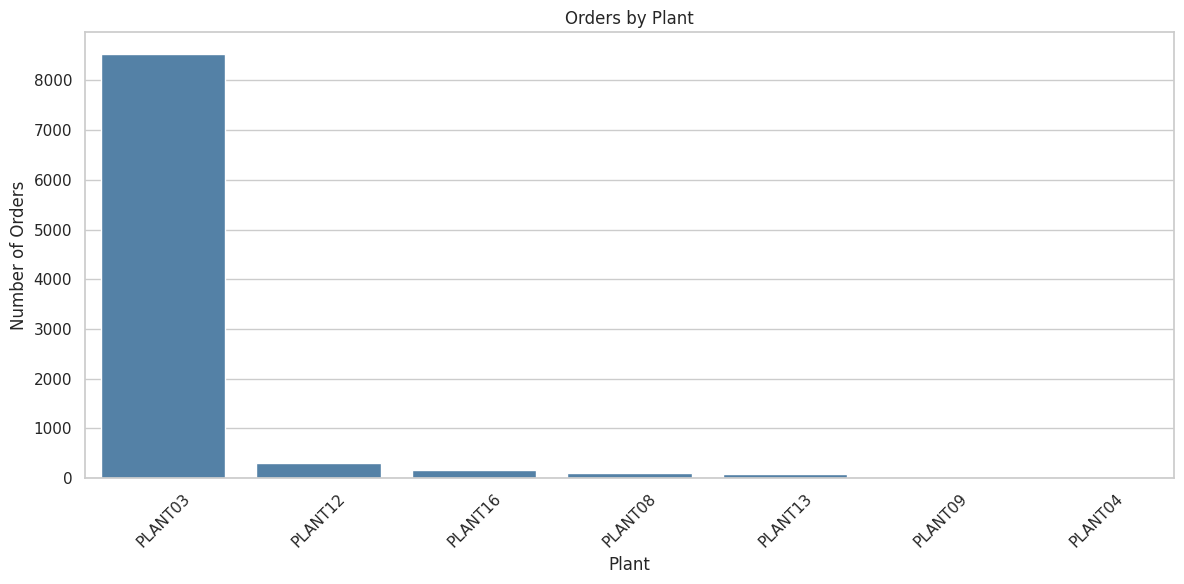

In [ ]:
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plant_demand,
    x="plant_code",
    y="total_orders",
    color="steelblue"
)

plt.title("Orders by Plant")
plt.xlabel("Plant")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2.2 產能利用率 Plant Capacity

In [ ]:
plant_capacity = plant_demand.merge(
    warehouse_capacities,
    on="plant_code",
    how="left"
)
plant_capacity

,plant_code,total_orders,total_units,total_weight,daily_capacity
0,PLANT03,8541,28611617,135486.511563,1013
1,PLANT12,300,112000,8147.429882,209
2,PLANT16,173,245133,32168.011913,457
3,PLANT08,102,277008,1478.787971,14
4,PLANT13,86,43379,5428.393538,490
5,PLANT09,12,223830,406.364549,11
6,PLANT04,1,348,2.101107,554


In [ ]:
plant_capacity["capacity_utilization_pct"] = (
    plant_capacity["total_orders"]
    / plant_capacity["daily_capacity"]
    * 100
)

plant_capacity["remaining_capacity"] = (
    plant_capacity["daily_capacity"]
    - plant_capacity["total_orders"]
)

plant_capacity["capacity_status"] = (
    plant_capacity["remaining_capacity"]
    .apply(
        lambda x: "Over Capacity"
        if x < 0
        else "Within Capacity"
    )
)

plant_capacity = plant_capacity.sort_values(
    "capacity_utilization_pct",
    ascending=False
)

display(
    plant_capacity[
        [
            "plant_code",
            "total_orders",
            "daily_capacity",
            "remaining_capacity",
            "capacity_utilization_pct",
            "capacity_status"
        ]
    ].round(2)
)

,plant_code,total_orders,daily_capacity,remaining_capacity,capacity_utilization_pct,capacity_status
0,PLANT03,8541,1013,-7528,843.14,Over Capacity
3,PLANT08,102,14,-88,728.57,Over Capacity
1,PLANT12,300,209,-91,143.54,Over Capacity
5,PLANT09,12,11,-1,109.09,Over Capacity
2,PLANT16,173,457,284,37.86,Within Capacity
4,PLANT13,86,490,404,17.55,Within Capacity
6,PLANT04,1,554,553,0.18,Within Capacity


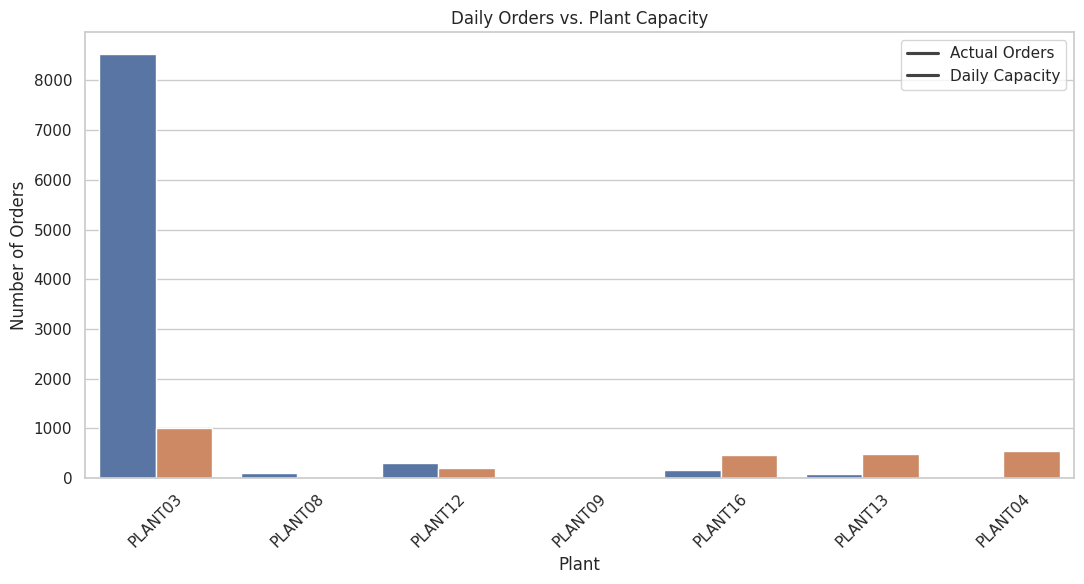

In [ ]:
capacity_long = plant_capacity.melt(
    id_vars="plant_code",
    value_vars=[
        "total_orders",
        "daily_capacity"
    ],
    var_name="metric",
    value_name="count"
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=capacity_long,
    x="plant_code",
    y="count",
    hue="metric",
    order=plant_capacity["plant_code"]
)

ax.set_title("Daily Orders vs. Plant Capacity")
ax.set_xlabel("Plant")
ax.set_ylabel("Number of Orders")
ax.legend(
    title="",
    labels=["Actual Orders", "Daily Capacity"]
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

plant_capacity["minimum_processing_days"] = np.ceil(
    plant_capacity["total_orders"]
    / plant_capacity["daily_capacity"]
).astype(int)

plant_capacity["first_day_backlog"] = (
    plant_capacity["total_orders"]
    - plant_capacity["daily_capacity"]
).clip(lower=0)

plant_capacity["capacity_status"] = np.where(
    plant_capacity["total_orders"]
    > plant_capacity["daily_capacity"],
    "Exceeds One-Day Capacity",
    "Within One-Day Capacity"
)

capacity_summary = plant_capacity[
    [
        "plant_code",
        "total_orders",
        "daily_capacity",
        "capacity_utilization_pct",
        "first_day_backlog",
        "minimum_processing_days",
        "capacity_status"
    ]
].sort_values(
    "minimum_processing_days",
    ascending=False
)

display(capacity_summary.round(2))

,plant_code,total_orders,daily_capacity,capacity_utilization_pct,first_day_backlog,minimum_processing_days,capacity_status
0,PLANT03,8541,1013,843.14,7528,9,Exceeds One-Day Capacity
3,PLANT08,102,14,728.57,88,8,Exceeds One-Day Capacity
1,PLANT12,300,209,143.54,91,2,Exceeds One-Day Capacity
5,PLANT09,12,11,109.09,1,2,Exceeds One-Day Capacity
2,PLANT16,173,457,37.86,0,1,Within One-Day Capacity
4,PLANT13,86,490,17.55,0,1,Within One-Day Capacity
6,PLANT04,1,554,0.18,0,1,Within One-Day Capacity


### Plant Capacity Findings｜工廠產能分析結果


*   共有四座工廠收到的訂單數超過其單日處理產能。其中，PLANT03 承擔的訂單量最高；在沒有新訂單持續進入的假設下。
Four plants received more orders than their stated one-day processing
capacity. PLANT03 had the largest workload and would require at least
9 processing days, while PLANT08 would require at least 8 days under
the assumption that no additional orders arrive.
*   此結果顯示供應鏈網路可能存在訂單積壓，以及工廠之間工作量分配
不均的情況。部分工廠的訂單量遠高於單日產能，其他工廠則仍有
未使用的處理能力。
This indicates potential backlog and uneven workload distribution
across the plant network. However, the actual completion or delay of
individual orders cannot be determined because processing sequence,
existing backlog, future arrivals, and actual completion dates are not
available.


*   然而，目前無法判斷每筆訂單實際完成或延遲的天數，因為資料並未
提供訂單處理順序、原有未完成訂單、後續新增訂單，以及實際完成
日期等資訊。因此，最低處理天數只代表在簡化假設下的估算結果，
不代表每筆訂單的實際延遲天數。
Because the orders represent historical routing while the capacity
table represents current constraints, this comparison is interpreted
as a capacity scenario rather than confirmed historical overload.
*   此外，Orders 資料表記錄的是歷史訂單配送情況，而 Warehouse
Capacities 資料表代表目前的工廠產能限制。 **因此本分析解讀為：
如果將這批歷史需求套用至目前的供應鏈限制，可能產生的產能壓力；
不能直接認定這些工廠在歷史上實際發生超載。**



## 2.3 各工廠延遲狀況

In [ ]:
plant_delivery_summary = (
    orders.groupby("plant_code")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "ship_late_day_count",
            lambda x: (x > 0).sum()
        ),
        average_late_days_all_orders=(
            "ship_late_day_count",
            "mean"
        ),
        average_late_days_when_late=(
            "ship_late_day_count",
            lambda x: x[x > 0].mean()
        ),
        average_ahead_days=(
            "ship_ahead_day_count",
            "mean"
        )
    )
    .reset_index()
)

plant_delivery_summary["late_rate_pct"] = (
    plant_delivery_summary["late_orders"]
    / plant_delivery_summary["total_orders"]
    * 100
)

display(
    plant_delivery_summary
    .sort_values("late_rate_pct", ascending=False)
    .round(2)
)

,plant_code,total_orders,late_orders,average_late_days_all_orders,average_late_days_when_late,average_ahead_days,late_rate_pct
2,PLANT08,102,18,0.23,1.28,0.71,17.65
0,PLANT03,8541,174,0.04,1.98,1.81,2.04
1,PLANT04,1,0,0.00,NaN,3.00,0.00
3,PLANT09,12,0,0.00,NaN,4.58,0.00
4,PLANT12,300,0,0.00,NaN,2.53,0.00
5,PLANT13,86,0,0.00,NaN,2.20,0.00
6,PLANT16,173,0,0.00,NaN,2.97,0.00


最重要的發現是：
- PLANT08 是配送穩定性風險最高的 Plant，約每六筆訂單就有一筆延遲。PLANT08 需優先改善準時率
- PLANT03 有 174 筆延遲，是延遲訂單的主要來源，但它承擔了整體約 92.69% 的訂單，因此延遲率只有 2.04%。
- PLANT04 只有一筆訂單，所以它的 0% 延遲率沒有太大比較意義。

# 3.顧客需求 Customer Demand Analysis

## 3.1 各顧客訂單量

In [ ]:
customer_orders = (
    orders.groupby("customer")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        unique_products=("product_id", "nunique"),
        plants_used=("plant_code", "nunique")
).reset_index().sort_values("total_orders", ascending=False)
)

customer_orders["order_share_pct"] = (
    customer_orders["total_orders"]
    / customer_orders["total_orders"].sum()
    * 100
)

customer_orders = customer_orders.sort_values(
    "total_orders",
    ascending=False
)

display(customer_orders.head(10).round(2))

,customer,total_orders,total_units,total_weight,unique_products,plants_used
7,V55555555555555_8,976,877824,12499.954655,72,2
29,V555555_6,762,1220461,16281.043281,178,5
31,V55555_2,758,1512452,18717.648999,132,5
23,V5555555_22,693,580326,6599.327384,50,1
37,V5555_33,691,241796,1240.170323,48,2
19,V55555555_7,618,927068,7765.270135,71,4
18,V55555555_5,531,8020417,21970.357577,133,3
13,V555555555_27,521,700796,7298.371246,100,1
5,V555555555555555_29,385,1054980,4425.115005,79,2
33,V55555_4,360,412940,5355.070993,89,3


## 3.2 顧客集中度（Concentration Risk）

Top 1 customer share: 10.59%
Top 5 customers share: 42.11%
Top 10 customers share: 68.31%


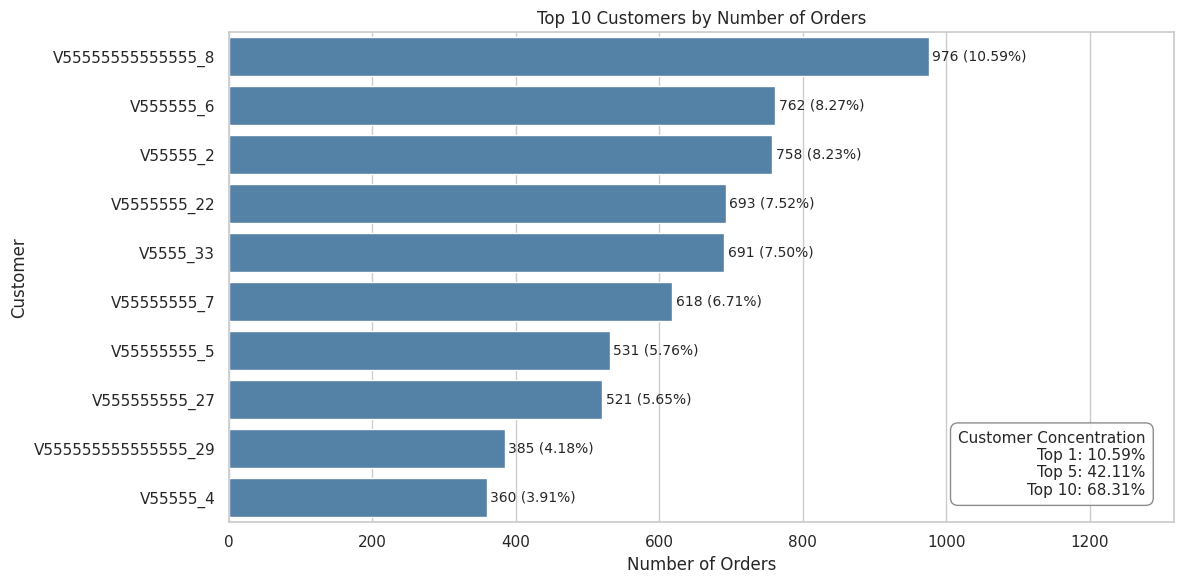

In [ ]:
top_10_customers = (
    customer_orders
    .nlargest(10, "total_orders")
    .sort_values("total_orders", ascending=False)
)

# 計算累積百分比
top_1_share = (
    customer_orders
    .nlargest(1, "total_orders")["total_orders"]
    .sum()
    / customer_orders["total_orders"].sum()
    * 100
)

top_5_share = (
    customer_orders
    .nlargest(5, "total_orders")["total_orders"]
    .sum()
    / customer_orders["total_orders"].sum()
    * 100
)

top_10_share = (
    customer_orders
    .nlargest(10, "total_orders")["total_orders"]
    .sum()
    / customer_orders["total_orders"].sum()
    * 100
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_customers,
    x="total_orders",
    y="customer",
    order=top_10_customers["customer"],
    color="steelblue"
)

print(f"Top 1 customer share: {top_1_share:.2f}%")
print(f"Top 5 customers share: {top_5_share:.2f}%")
print(f"Top 10 customers share: {top_10_share:.2f}%")

# 每位顧客：訂單數與個別占比
for bar, (_, row) in zip(
    ax.patches,
    top_10_customers.iterrows()
):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total_orders']:,.0f} "
        f"({row['order_share_pct']:.2f}%)",
        va="center",
        fontsize=10
    )

# 留空間給數字
max_orders = top_10_customers["total_orders"].max()

ax.set_xlim(
    0,
    max_orders * 1.35
)

# 累積占比摘要文字
concentration_text = (
    f"Customer Concentration\n"
    f"Top 1: {top_1_share:.2f}%\n"
    f"Top 5: {top_5_share:.2f}%\n"
    f"Top 10: {top_10_share:.2f}%"
)

# 把摘要框放在右下角
ax.text(
    0.97,
    0.05,
    concentration_text,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "gray",
        "alpha": 0.9
    }
)

ax.set_title("Top 10 Customers by Number of Orders")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("Customer")

plt.tight_layout()
plt.show()

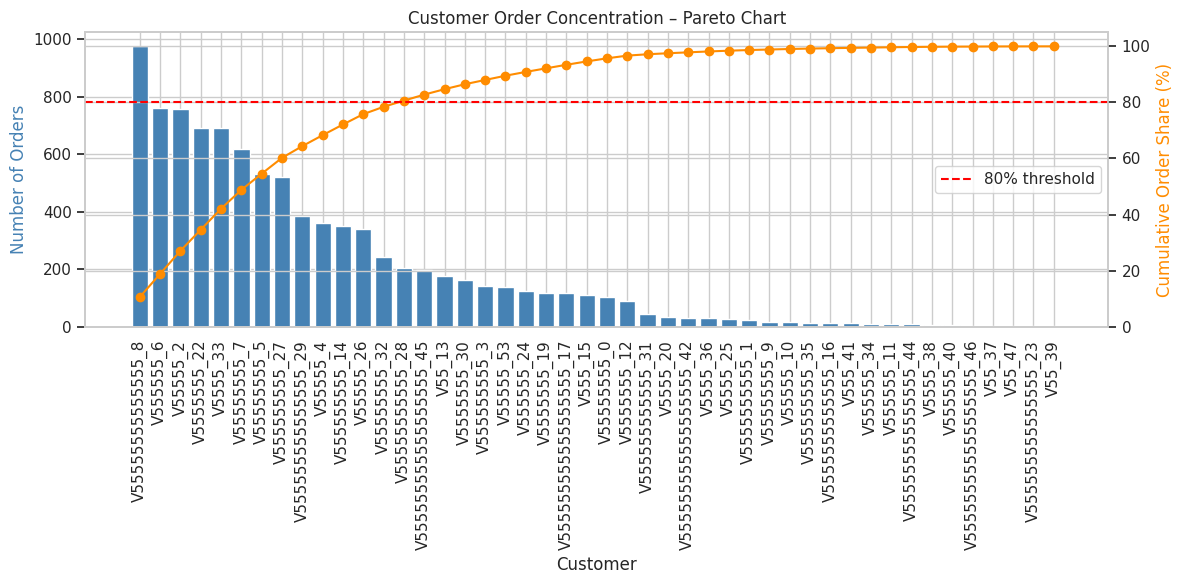

In [ ]:
customer_pareto = (
    customer_orders
    .sort_values("total_orders", ascending=False)
    .reset_index(drop=True)
)

customer_pareto["cumulative_order_share_pct"] = (
    customer_pareto["total_orders"].cumsum()
    / customer_pareto["total_orders"].sum()
    * 100
)

import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

# 每位顧客的訂單量
ax1.bar(
    customer_pareto["customer"],
    customer_pareto["total_orders"],
    color="steelblue"
)

ax1.set_xlabel("Customer")
ax1.set_ylabel(
    "Number of Orders",
    color="steelblue"
)

ax1.tick_params(
    axis="x",
    rotation=90
)

# 累積訂單比例
ax2 = ax1.twinx()

ax2.plot(
    customer_pareto["customer"],
    customer_pareto["cumulative_order_share_pct"],
    color="darkorange",
    marker="o"
)

ax2.axhline(
    80,
    color="red",
    linestyle="--",
    label="80% threshold"
)

ax2.set_ylabel(
    "Cumulative Order Share (%)",
    color="darkorange"
)

ax2.set_ylim(0, 105)
ax2.legend(loc="center right")

plt.title("Customer Order Concentration – Pareto Chart")
plt.tight_layout()
plt.show()

### Customer Concentration Findings｜顧客集中度分析

**English**

Customer demand is moderately concentrated. The largest customer
accounts for approximately 10% of total orders, while the top 10
customers collectively contribute around two-thirds of all orders.
Approximately 14 customers are required to reach 80% of cumulative
order volume.

This indicates that the company depends on a group of high-volume
customers rather than a single dominant customer.

**中文**

顧客需求呈現中度集中。最大顧客約占總訂單量的 10%，前 10 名
顧客合計約占全部訂單的三分之二，而累積訂單占比達到 80% 約需
前 14 名顧客。

這表示公司主要依賴一群高訂單量顧客，而非過度依賴單一顧客。
後續應檢查這些主要顧客是否集中由特定工廠服務，以及其 VMI
工廠配置是否符合目前的供應鏈限制。 後續檢查主要顧客是否集中由特定工廠服務。

#4.VMI 顧客 vs 非 VMI 顧客

## 顧客&VMI配置

- 哪些歷史訂單符合目前的 VMI Customer–Plant 配置
- 哪些 VMI 顧客使用了不同工廠
- 哪些訂單來自一般非 VMI 顧客？

In [ ]:
vmi_pairs = (
    vmi_customers[
        ["customer", "plant_code"]
    ]
    .drop_duplicates()
)

orders_vmi = orders.merge(
    vmi_pairs,
    on=["customer", "plant_code"],
    how="left",
    indicator=True,
    validate="many_to_one"
)

orders_vmi["is_vmi_plant_match"] = (
    orders_vmi["_merge"] == "both"
)

orders_vmi = orders_vmi.drop(
    columns="_merge"
)

In [ ]:
vmi_customer_set = set(
    vmi_customers["customer"]
)

orders_vmi["vmi_status"] = np.select(
    [
        orders_vmi["is_vmi_plant_match"],
        orders_vmi["customer"].isin(vmi_customer_set)
    ],
    [
        "VMI Plant Match",
        "VMI Customer - Different Plant"
    ],
    default="Non-VMI Customer"
)

In [ ]:
vmi_status_order = [
    "VMI Plant Match",
    "VMI Customer - Different Plant",
    "Non-VMI Customer"
]

vmi_summary = (
    orders_vmi.groupby("vmi_status")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum")
    )
    .reindex(
        vmi_status_order,
        fill_value=0
    )
    .reset_index()
)

vmi_summary["order_share_pct"] = (
    vmi_summary["total_orders"]
    / vmi_summary["total_orders"].sum()
    * 100
)

display(vmi_summary.round(2))

,vmi_status,total_orders,unique_customers,total_units,total_weight,order_share_pct
0,VMI Plant Match,0,0,0,0.00,0.00
1,VMI Customer - Different Plant,2089,8,10049840,43620.34,22.67
2,Non-VMI Customer,7126,38,19463475,139497.26,77.33


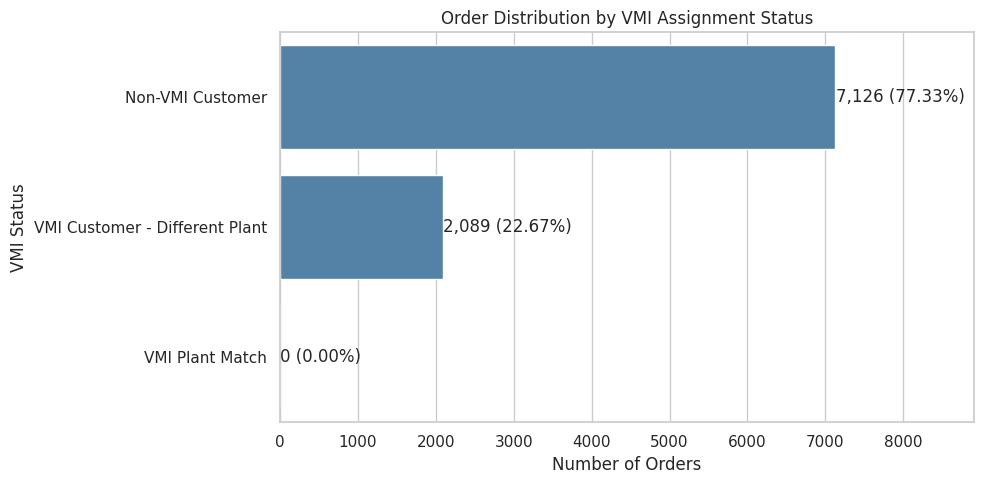

In [ ]:
vmi_summary = vmi_summary.sort_values(
    "total_orders",
    ascending=False
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=vmi_summary,
    x="total_orders",
    y="vmi_status",
    order=vmi_summary["vmi_status"],
    color="steelblue"
)

for bar, (_, row) in zip(
    ax.patches,
    vmi_summary.iterrows()
):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total_orders']:,.0f} "
        f"({row['order_share_pct']:.2f}%)",
        va="center"
    )

ax.set_xlim(
    0,
    vmi_summary["total_orders"].max() * 1.25
)

ax.set_title("Order Distribution by VMI Assignment Status")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("VMI Status")

plt.tight_layout()
plt.show()

In [ ]:
print(sorted(vmi_customers["plant_code"].unique()))
print(sorted(orders.loc[orders["customer"].isin(vmi_customers["customer"]), "plant_code"].unique()))

NameError: name 'vmi_customers' is not defined

### VMI Customer Analysis — Findings 1(order customer and vim assignment relationships)

- 共有 **2,089 筆訂單（22.67%）** 來自目前 VMI 名單中的 **8 位顧客**。 A total of  **2,089 orders (22.67%)** were placed by **8 customers identified in the current VMI customer table**.
- 但是，這些歷史訂單所使用的工廠，都沒有與目前 VMI 表中指定的工廠相同，因此 **VMI 工廠完全符合的訂單為 0 筆**。 However, none of these historical orders were assigned to the same plant specified in the current VMI configuration. Therefore, the number of **VMI Plant Match orders is 0**.
- 另外 **7,126 筆訂單（77.33%）** 來自 **38 位非 VMI 顧客**，並占大部分的訂購數量與運輸重量。 The remaining **7,126 orders (77.33%)** came from **38 non-VMI customers**. Non-VMI customers also accounted for the majority of total units and shipment weight.

這個結果不一定代表歷史訂單分配錯誤。因為訂單表是歷史資料，而 VMI 表可能代表目前的顧客—工廠配置。0 筆符合可能表示 VMI 配置曾經調整，或當時訂單使用了不同的分配規則。若要判斷歷史訂單是否違反 VMI 規則，還需要取得歷史 VMI 配置及其生效日期。

This does not necessarily indicate incorrect historical routing. The order table contains historical transactions, while the VMI customer table represents the current customer-to-plant assignments. The zero match may indicate that VMI assignments changed over time or that historical orders were routed using different business rules.

Further analysis would require historical VMI assignment records or effective dates to determine whether the historical routing complied with the VMI rules applicable at that time.

## 4.2 VMI 與非 VMI 顧客比較（不限定工廠

In [ ]:
# 取得 VMI 顧客名單
vmi_customer_list = set(vmi_customers["customer"].dropna().unique())

# 依照顧客是否存在於 VMI 名單分類
orders_vmi_analysis = orders.copy()

orders_vmi_analysis["customer_type"] = (
    orders_vmi_analysis["customer"]
    .isin(vmi_customer_list)
    .map({
        True: "VMI Customer",
        False: "Non-VMI Customer"
    })
)

orders_vmi_analysis["customer_type"].value_counts()

,count
customer_type,
Non-VMI Customer,7126
VMI Customer,2089


#### 訂單量

In [ ]:
customer_order_summary = (
    orders_vmi_analysis
    .groupby(["customer_type", "customer"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum")
    )
    .reset_index()
)

order_comparison = (
    customer_order_summary
    .groupby("customer_type")
    .agg(
        unique_customers=("customer", "nunique"),
        total_orders=("total_orders", "sum"),
        average_orders_per_customer=("total_orders", "mean"),
        median_orders_per_customer=("total_orders", "median"),
        average_units_per_customer=("total_units", "mean"),
        average_weight_per_customer=("total_weight", "mean")
    )
    .reset_index()
)

display(order_comparison.round(2))

,customer_type,unique_customers,total_orders,average_orders_per_customer,median_orders_per_customer,average_units_per_customer,average_weight_per_customer
0,Non-VMI Customer,38,7126,187.53,106.0,512196.71,3670.98
1,VMI Customer,8,2089,261.12,79.0,1256230.00,5452.54


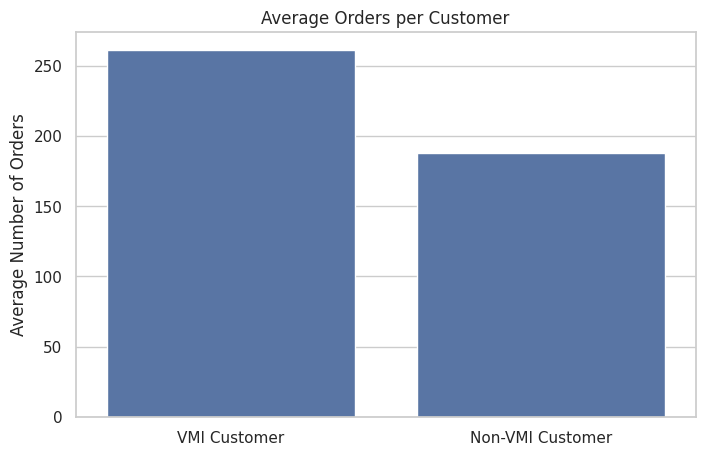

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.barplot(
    data=order_comparison,
    x="customer_type",
    y="average_orders_per_customer",
    order=["VMI Customer", "Non-VMI Customer"]
)

plt.title("Average Orders per Customer")
plt.xlabel("")
plt.ylabel("Average Number of Orders")
plt.show()

VMI 顧客人數較少，但平均每人訂單數較高（261 vs. 188），需求較集中

Although VMI customers represent a smaller customer group, they generate more orders per customer, indicating higher individual demand concentration.

#### 運輸天數

In [ ]:
transport_comparison = (
    orders_vmi_analysis
    .groupby("customer_type")
    .agg(
        total_orders=("order_id", "nunique"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        min_transport_days=("transport_days", "min"),
        max_transport_days=("transport_days", "max")
    )
    .reset_index()
)

display(transport_comparison.round(2))

,customer_type,total_orders,average_transport_days,median_transport_days,min_transport_days,max_transport_days
0,Non-VMI Customer,7126,1.75,2.0,0,4
1,VMI Customer,2089,1.61,2.0,0,4


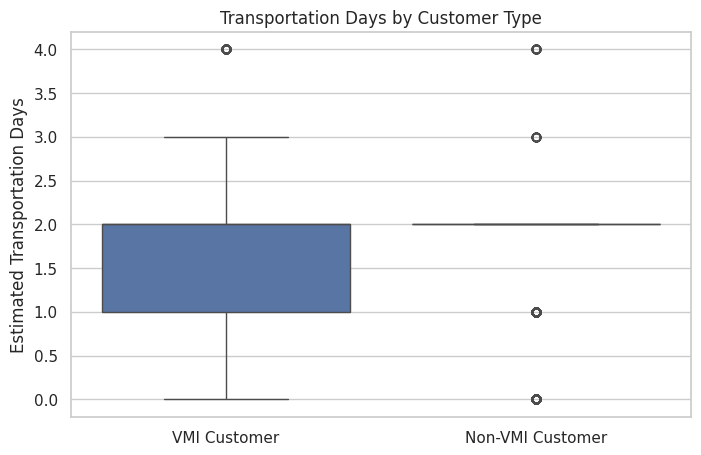

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=orders_vmi_analysis,
    x="customer_type",
    y="transport_days",
    order=["VMI Customer", "Non-VMI Customer"]
)

plt.title("Transportation Days by Customer Type")
plt.xlabel("")
plt.ylabel("Estimated Transportation Days")
plt.show()

原始資料中包含運輸天數為 0 的訂單，因此這些數值並非資料清理過程所造成。

0 天可能代表當日送達，或實際運輸時間不足一個完整天數，因此在來源系統中記錄為 0。由於資料說明未提供時間計算及進位方式，本分析保留這些紀錄，但不將其直接視為已確認的當日送達。

In [ ]:
transport_distribution = (
    orders_vmi_analysis
    .groupby(["customer_type", "transport_days"])
    .size()
    .reset_index(name="order_count")
)

transport_distribution["percentage"] = (
    transport_distribution["order_count"]
    / transport_distribution
        .groupby("customer_type")["order_count"]
        .transform("sum")
    * 100
)

display(transport_distribution.round(2))

,customer_type,transport_days,order_count,percentage
0,Non-VMI Customer,0,350,4.91
1,Non-VMI Customer,1,1204,16.90
2,Non-VMI Customer,2,5497,77.14
3,Non-VMI Customer,3,30,0.42
4,Non-VMI Customer,4,45,0.63
5,VMI Customer,0,61,2.92
6,VMI Customer,1,919,43.99
7,VMI Customer,2,983,47.06
8,VMI Customer,3,28,1.34
9,VMI Customer,4,98,4.69


#### 倉儲成本

In [ ]:
orders_cost_analysis = orders_vmi_analysis.merge(
    warehouse_costs[["plant_code", "cost_unit"]],
    on="plant_code",
    how="left",
    validate="many_to_one"
)

print("Missing cost records:")
print(orders_cost_analysis["cost_unit"].isna().sum())

Missing cost records:
0


In [ ]:
orders_cost_analysis["estimated_warehouse_cost"] = (
    orders_cost_analysis["unit_quantity"]
    * orders_cost_analysis["cost_unit"]
)

cost_comparison = (
    orders_cost_analysis
    .groupby("customer_type")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_estimated_warehouse_cost=(
            "estimated_warehouse_cost", "sum"
        ),
        average_cost_per_order=(
            "estimated_warehouse_cost", "mean"
        ),
        average_cost_per_unit=("cost_unit", "mean")
    )
    .reset_index()
)

display(cost_comparison.round(2))

,customer_type,total_orders,total_units,total_estimated_warehouse_cost,average_cost_per_order,average_cost_per_unit
0,Non-VMI Customer,7126,19463475,10414949.09,1461.54,0.56
1,VMI Customer,2089,10049840,5218272.82,2497.98,0.54


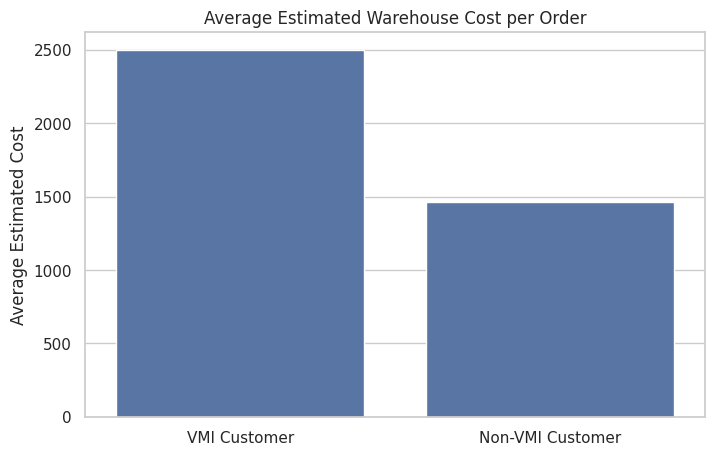

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cost_comparison,
    x="customer_type",
    y="average_cost_per_order",
    order=["VMI Customer", "Non-VMI Customer"]
)

plt.title("Average Estimated Warehouse Cost per Order")
plt.xlabel("")
plt.ylabel("Average Estimated Cost")
plt.show()

final summary

In [ ]:
vmi_final_comparison = (
    orders_cost_analysis
    .groupby("customer_type")
    .agg(
        unique_customers=("customer", "nunique"),
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        average_weight_per_order=("weight", "mean"),
        average_cost_per_order=("estimated_warehouse_cost", "mean"),
        total_estimated_warehouse_cost=(
            "estimated_warehouse_cost", "sum"
        )
    )
    .reset_index()
)

vmi_final_comparison["orders_per_customer"] = (
    vmi_final_comparison["total_orders"]
    / vmi_final_comparison["unique_customers"]
)

vmi_final_comparison["average_units_per_order"] = (
    vmi_final_comparison["total_units"]
    / vmi_final_comparison["total_orders"]
)

vmi_final_comparison["estimated_cost_per_unit"] = (
    vmi_final_comparison["total_estimated_warehouse_cost"]
    / vmi_final_comparison["total_units"]
)

display(vmi_final_comparison.round(2))

,customer_type,unique_customers,total_orders,total_units,average_transport_days,median_transport_days,average_weight_per_order,average_cost_per_order,total_estimated_warehouse_cost,orders_per_customer,average_units_per_order,estimated_cost_per_unit
0,Non-VMI Customer,38,7126,19463475,1.75,2.0,19.58,1461.54,10414949.09,187.53,2731.33,0.54
1,VMI Customer,8,2089,10049840,1.61,2.0,20.88,2497.98,5218272.82,261.12,4810.84,0.52


### VMI vs. Non-VMI Customer Analysis  
### VMI 與非 VMI 顧客比較

- 資料中包含 **8 位 VMI 顧客**及 **38 位非 VMI 顧客**。
- VMI 顧客平均每人產生 **261.12 筆訂單**，比非 VMI 顧客的 **187.53 筆**高約 **39.2%**，顯示 VMI 顧客的個別需求較集中。
- VMI 訂單的平均運輸時間為 **1.61 天**，略短於非 VMI 訂單的 **1.75 天**。
- 兩組的運輸時間中位數皆為 **2 天**，表示典型訂單的運輸時間差異有限。
- VMI 訂單的平均重量為 **20.88**，比非 VMI 訂單的 **19.58**高約 **6.6%**。
- VMI 每筆訂單的估計倉儲成本為 **2,497.98**，比非 VMI 的 **1,461.54**高約 **70.9%**。
- 不過，VMI 每筆訂單約包含 **4,811 units**，明顯高於非 VMI 每筆訂單的約 **2,731 units**。
- VMI 的估計單位成本約為 **0.52**，非 VMI 約為 **0.54**，顯示 VMI 訂單可能具有輕微的規模效益。
- 由於本分析結合了歷史訂單與目前的 VMI 配置及倉儲成本，因此結果代表關聯及情境比較，不能直接證明 VMI 導致運輸時間或成本的變化。


- The dataset includes **8 VMI customers** and **38 non-VMI customers**.
- VMI customers placed an average of **261.12 orders per customer**, approximately **39.2% more** than the **187.53 orders** placed by each non-VMI customer.
- VMI orders had a slightly shorter average transportation time of **1.61 days**, compared with **1.75 days** for non-VMI orders.
- Both groups had a median transportation time of **2 days**, indicating that the difference in typical transportation time was limited.
- The average VMI order weighed **20.88**, approximately **6.6% more** than the average non-VMI order weight of **19.58**.
- The estimated warehouse cost per VMI order was **2,497.98**, approximately **70.9% higher** than the **1,461.54** estimated for non-VMI orders.
- However, VMI orders contained approximately **4,811 units per order**, compared with approximately **2,731 units per non-VMI order**.
- The estimated cost per unit was approximately **0.52 for VMI orders** and **0.54 for non-VMI orders**, suggesting a small potential scale advantage for VMI orders.
- These findings show association rather than causation because the analysis combines historical orders with current VMI assignments and warehouse-cost constraints.


# 5.產品需求與供應風險 Product & Plant Analysis

##5.1 產品需求排名 Product Demand

In [ ]:
product_summary = (
    orders.groupby("product_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        unique_customers=("customer", "nunique"),
        plants_used=("plant_code", "nunique")
    )
    .reset_index()
    .sort_values("total_units", ascending=False)
)

display(product_summary.head(10))

,product_id,total_orders,total_units,total_weight,unique_customers,plants_used
380,1684862,16,3470409,4197.921677,2,1
241,1676592,22,1119252,590.600766,1,1
754,1700569,3,904493,1053.370000,2,1
120,1664051,37,873011,10567.708487,2,1
145,1667927,20,814076,439.441223,1,1
745,1700140,17,811381,555.024424,3,1
361,1683560,30,772283,7787.744564,1,1
134,1666524,19,670437,367.046207,1,1
741,1700130,9,658352,638.906571,2,1
748,1700143,10,654556,593.417787,2,1


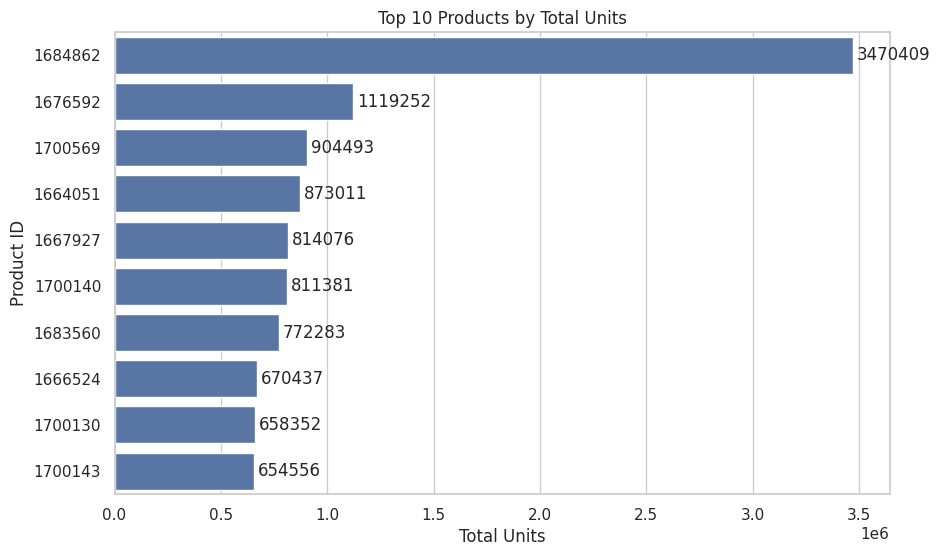

In [ ]:
top_10_products = product_summary.head(10).copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_10_products,
    x="total_units",
    y="product_id",
    color="#4C72B0"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3
    )

plt.title("Top 10 Products by Total Units")
plt.xlabel("Total Units")
plt.ylabel("Product ID")
plt.show()

In [ ]:
product_summary["unit_share_pct"] = (
    product_summary["total_units"]
    / product_summary["total_units"].sum()
    * 100
)

product_summary["cumulative_unit_share_pct"] = (
    product_summary["unit_share_pct"].cumsum()
)

top_product_concentration = pd.DataFrame({
    "group": ["Top 1", "Top 5", "Top 10"],
    "cumulative_unit_share_pct": [
        product_summary.head(1)["unit_share_pct"].sum(),
        product_summary.head(5)["unit_share_pct"].sum(),
        product_summary.head(10)["unit_share_pct"].sum()
    ]
})

display(top_product_concentration.round(2))

,group,cumulative_unit_share_pct
0,Top 1,11.76
1,Top 5,24.33
2,Top 10,36.42


## 5.2 各產品可供應工廠數（供應中斷風險）

每項產品可由多少工廠供應 判斷是否有供應中斷的風險

In [ ]:
product_plant_availability = (
    products_per_plant
    .groupby("product_id")
    .agg(
        available_plants=("plant_code", "nunique")
    )
    .reset_index()
)

product_risk = product_summary.merge(
    product_plant_availability,
    on="product_id",
    how="left",
    validate="one_to_one"
)

product_risk["available_plants"] = (
    product_risk["available_plants"]
    .fillna(0)
    .astype(int)
)

product_risk["supply_risk"] = pd.cut(
    product_risk["available_plants"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=[
        "No Available Plant",
        "Single-Plant Dependency",
        "Two Available Plants",
        "Diversified"
    ]
)

display(
    product_risk.sort_values(
        ["available_plants", "total_units"],
        ascending=[True, False]
    ).head(20)
)

,product_id,total_orders,total_units,total_weight,unique_customers,plants_used,unit_share_pct,cumulative_unit_share_pct,available_plants,supply_risk
0,1684862,16,3470409,4197.921677,2,1,11.758791,11.758791,1,Single-Plant Dependency
1,1676592,22,1119252,590.600766,1,1,3.792363,15.551154,1,Single-Plant Dependency
2,1700569,3,904493,1053.370000,2,1,3.064695,18.615848,1,Single-Plant Dependency
3,1664051,37,873011,10567.708487,2,1,2.958024,21.573873,1,Single-Plant Dependency
4,1667927,20,814076,439.441223,1,1,2.758335,24.332207,1,Single-Plant Dependency
5,1700140,17,811381,555.024424,3,1,2.749203,27.081411,1,Single-Plant Dependency
6,1683560,30,772283,7787.744564,1,1,2.616727,29.698138,1,Single-Plant Dependency
7,1666524,19,670437,367.046207,1,1,2.271642,31.969780,1,Single-Plant Dependency
8,1700130,9,658352,638.906571,2,1,2.230695,34.200475,1,Single-Plant Dependency
9,1700143,10,654556,593.417787,2,1,2.217833,36.418308,1,Single-Plant Dependency


In [ ]:
risk_label_summary = (
    product_risk
    .groupby("supply_risk", observed=False)
    .agg(
        product_count=("product_id", "nunique"),
        products=(
            "product_id",
            lambda values: ", ".join(
                sorted(values.astype(str).unique())
            )
        )
    )
    .reset_index()
)

display(risk_label_summary)

,supply_risk,product_count,products
0,No Available Plant,0,
1,Single-Plant Dependency,614,"1613321, 1615677, 1617714, 1617826, 1620510, 1..."
2,Two Available Plants,82,"1621719, 1655985, 1660153, 1660585, 1660668, 1..."
3,Diversified,76,"1672344, 1672986, 1681878, 1681883, 1682651, 1..."


### 5. 產品需求與供應風險｜發現

- 資料中共有 **772 項產品**。需求量最大的產品 1684862 占總需求單位數的 **11.76%**，且只有 1 座工廠可供應。
- 依「可供應工廠數」分級：
  - **Single-Plant Dependency（僅 1 座工廠可供應）**：614 項產品，約占產品數的 **79.5%**，占需求單位數的 **90.4%**。
  - **Two Available Plants（2 座工廠）**：82 項。
  - **Diversified（3 座以上）**：76 項。
- 也就是說，**絕大多數需求集中在單一工廠供應的產品**。這與第 2 章的產能壓力互相呼應：一旦該工廠超載或中斷，沒有備援工廠可以分擔。
- **建議**：優先針對高需求的單廠產品，評估是否能在其他工廠建立供應能力，或建立安全庫存。
- **限制**：「可供應工廠」只代表目前產品—工廠配置，無法得知其他工廠實際的產能餘裕與切換成本。

# 6.承運商、路線與 Service Level 分析

## 6.1 承運商運輸時間

不同承運商的運輸時間

In [ ]:
orders_delivery = orders.copy()

orders_delivery["route"] = (
    orders_delivery["origin_port"]
    + " → "
    + orders_delivery["destination_port"]
)

In [ ]:
carrier_performance = (
    orders_delivery
    .groupby("carrier")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        min_transport_days=("transport_days", "min"),
        max_transport_days=("transport_days", "max"),
        unique_routes=("route", "nunique"),
        service_levels=("service_level", "nunique")
    )
    .reset_index()
    .sort_values("average_transport_days")
)

carrier_performance["order_share_pct"] = (
    carrier_performance["total_orders"]
    / carrier_performance["total_orders"].sum()
    * 100
)

display(carrier_performance.round(2))

,carrier,total_orders,total_units,total_weight,average_transport_days,median_transport_days,min_transport_days,max_transport_days,unique_routes,service_levels,order_share_pct
1,V444_1,2097,2089040,26574.50,1.05,1.0,1,2,1,1,22.76
2,V44_3,854,3810886,35102.65,1.29,1.0,0,4,3,1,9.27
0,V444_0,6264,23613389,121440.44,2.00,2.0,0,3,2,2,67.98


carrier 平均運輸天數

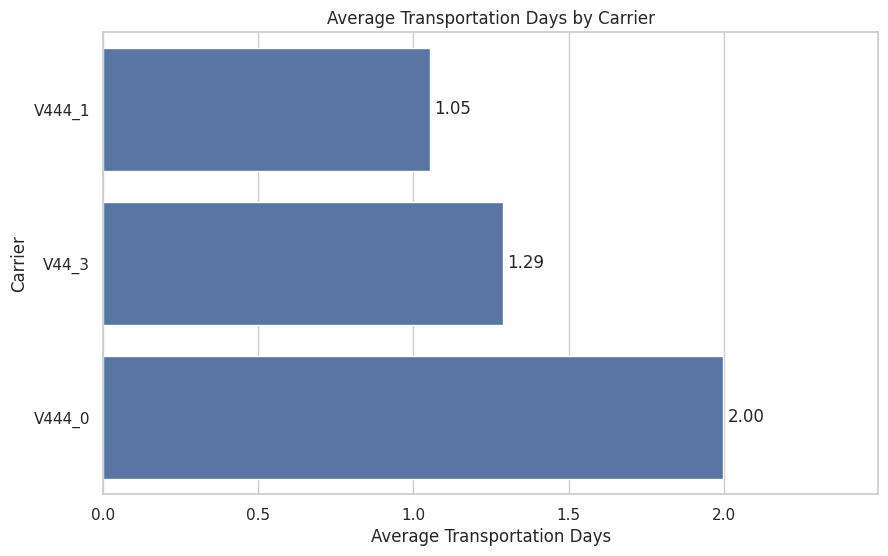

In [ ]:
carrier_plot = carrier_performance.sort_values(
    "average_transport_days"
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=carrier_plot,
    x="average_transport_days",
    y="carrier",
    color="#4C72B0"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

plt.title("Average Transportation Days by Carrier")
plt.xlabel("Average Transportation Days")
plt.ylabel("Carrier")
plt.xlim(
    0,
    carrier_plot["average_transport_days"].max() + 0.5
)

plt.show()

從歷史訂單中可以得出總共只有三個carrier 訂單數最多的是V444_0 (67.98%),平均運輸天數是最多的2天, 再者是V444_1(22.76%) 平均僅需1.05天 為最少 -- 但也需要考慮可能因為產品不同或是重量?

## 6.2 路線分析

歷史訂單中 orgin_port - destinaiton_prot 路線的數量

In [ ]:
route_summary = (
    orders_delivery
    .groupby([
        "origin_port",
        "destination_port",
        "route"
    ])
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        min_transport_days=("transport_days", "min"),
        max_transport_days=("transport_days", "max"),
        unique_carriers=("carrier", "nunique"),
        unique_customers=("customer", "nunique")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

route_summary["order_share_pct"] = (
    route_summary["total_orders"]
    / route_summary["total_orders"].sum()
    * 100
)

display(route_summary.round(2))

NameError: name 'orders_delivery' is not defined

In [ ]:
routes_propotion = route_summary.head(10).copy()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=routes_propotion,
    x="total_orders",
    y="route",
    color="#55A868"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3
    )

plt.title("Most Frequently Used Routes")
plt.xlabel("Number of Orders")
plt.ylabel("Route")
plt.show()

NameError: name 'route_summary' is not defined

哪些路線的運輸時間最長

In [ ]:
longest_routes = (
    route_summary
    .sort_values(
        [
            "average_transport_days",
            "total_orders"
        ],
        ascending=[False, False]
    )
)

display(
    longest_routes[[
        "route",
        "total_orders",
        "average_transport_days",
        "median_transport_days",
        "min_transport_days",
        "max_transport_days",
        "unique_carriers"
    ]].head(10).round(2)
)

,route,total_orders,average_transport_days,median_transport_days,min_transport_days,max_transport_days,unique_carriers
1,PORT05 → PORT09,1,2.00,2.0,2,2,1
0,PORT04 → PORT09,9041,1.74,2.0,0,4,3
2,PORT09 → PORT09,173,0.80,1.0,0,1,2


從歷史訂單的路線來看只有三種運輸路徑 最多的佔了98% 幾乎為所有訂單都是從port4 到 port9
--PORT04→PORT09 佔 98.11%，路線高度集中；成本比較見第 8 章。

## 6.3 Service Level 與運輸時間

In [ ]:
service_level_summary = (
    orders_delivery
    .groupby("service_level")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        min_transport_days=("transport_days", "min"),
        max_transport_days=("transport_days", "max"),
        unique_carriers=("carrier", "nunique"),
        unique_routes=("route", "nunique")
    )
    .reset_index()
    .sort_values("average_transport_days")
)

service_level_summary["order_share_pct"] = (
    service_level_summary["total_orders"]
    / service_level_summary["total_orders"].sum()
    * 100
)

display(service_level_summary.round(2))

,service_level,total_orders,total_units,total_weight,average_transport_days,median_transport_days,min_transport_days,max_transport_days,unique_carriers,unique_routes,order_share_pct
1,DTD,2143,2773851,27745.38,1.09,1.0,1,3,2,1,23.26
0,CRF,854,3810886,35102.65,1.29,1.0,0,4,1,3,9.27
2,DTP,6218,22928578,120269.57,1.99,2.0,0,3,1,2,67.48


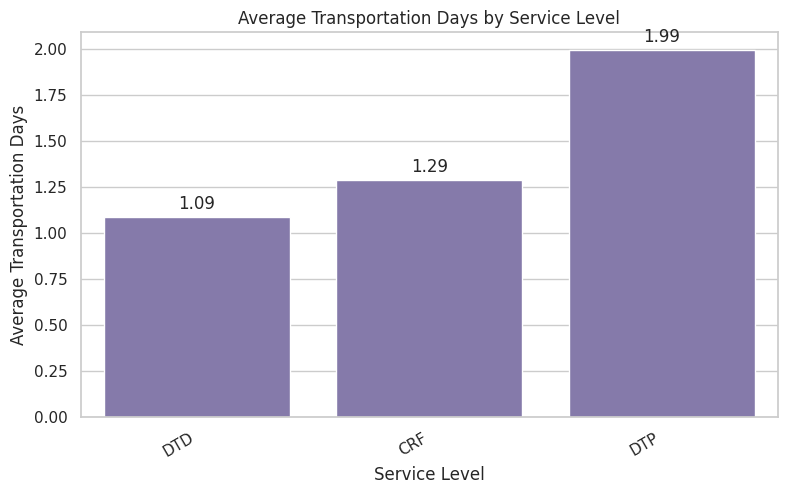

In [ ]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=service_level_summary,
    x="service_level",
    y="average_transport_days",
    order=service_level_summary["service_level"],
    color="#8172B2"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

plt.title("Average Transportation Days by Service Level")
plt.xlabel("Service Level")
plt.ylabel("Average Transportation Days")
plt.xticks(rotation=30, ha="right")
plt.show()

### 同一路線內比較

In [ ]:
route_service_comparison = (
    orders_delivery
    .groupby([
        "route",
        "service_level"
    ])
    .agg(
        total_orders=("order_id", "nunique"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        unique_carriers=("carrier", "nunique")
    )
    .reset_index()
)

display(
    route_service_comparison.sort_values(
        ["route", "average_transport_days"]
    ).round(2)
)

,route,service_level,total_orders,average_transport_days,median_transport_days,unique_carriers
1,PORT04 → PORT09,DTD,2143,1.09,1.0,2
0,PORT04 → PORT09,CRF,714,1.34,0.0,1
2,PORT04 → PORT09,DTP,6184,2.00,2.0,1
3,PORT05 → PORT09,CRF,1,2.00,2.0,1
5,PORT09 → PORT09,DTP,34,0.00,0.0,1
4,PORT09 → PORT09,CRF,139,1.00,1.0,1


### 多 Service Level 的路線

In [ ]:
comparable_routes = (
    route_service_comparison
    .groupby("route")
    .filter(
        lambda group:
        group["service_level"].nunique() > 1
    )
)

display(
    comparable_routes.sort_values(
        ["route", "average_transport_days"]
    ).round(2)
)

,route,service_level,total_orders,average_transport_days,median_transport_days,unique_carriers
1,PORT04 → PORT09,DTD,2143,1.09,1.0,2
0,PORT04 → PORT09,CRF,714,1.34,0.0,1
2,PORT04 → PORT09,DTP,6184,2.00,2.0,1
5,PORT09 → PORT09,DTP,34,0.00,0.0,1
4,PORT09 → PORT09,CRF,139,1.00,1.0,1


最多的service level 為DTP 67.48% DTD 23%

同一種SERVICE有不同的路線: 從PORT4-PORT9都有這三種SERVICE LEVEL, 在 PORT04→PORT09 上，DTP 平均約 2 天，CRF 與 DTD 較短；但在 PORT09→PORT09，DTD 反而比 CRF 快，顯示 Service Level 與運輸時間的關係受路線影響，不應只看整體平均。

## 6.4 進階檢查：控制重量與產品後的 Carrier 比較

Carrier × Service Level Heatmap

In [ ]:
carrier_service_heatmap = orders_delivery.pivot_table(
    index="carrier",
    columns="service_level",
    values="transport_days",
    aggfunc="mean"
)

display(carrier_service_heatmap.round(2))

service_level,CRF,DTD,DTP
carrier,,,
V444_0,NaN,2.65,1.99
V444_1,NaN,1.05,NaN
V44_3,1.29,NaN,NaN


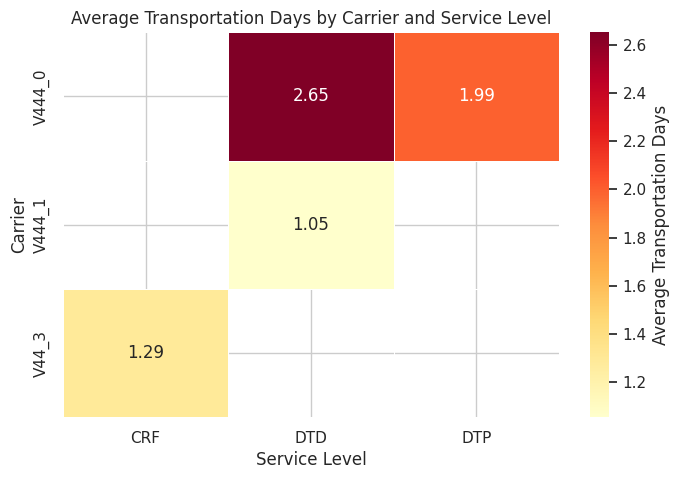

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    carrier_service_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={
        "label": "Average Transportation Days"
    }
)

plt.title("Average Transportation Days by Carrier and Service Level")
plt.xlabel("Service Level")
plt.ylabel("Carrier")
plt.show()

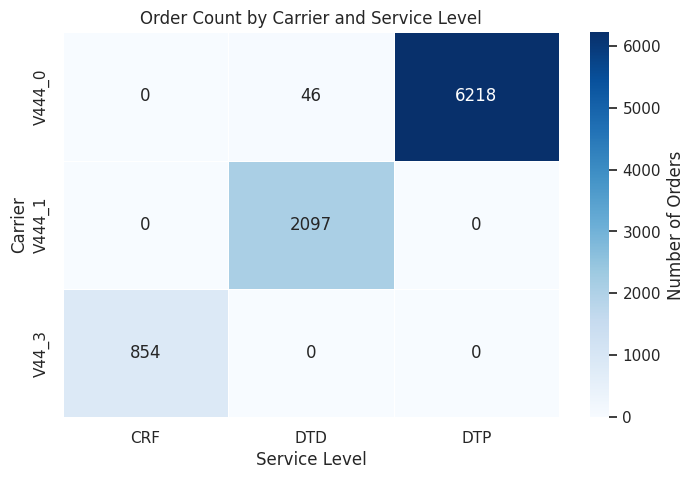

In [ ]:
carrier_service_count = orders_delivery.pivot_table(
    index="carrier",
    columns="service_level",
    values="order_id",
    aggfunc="nunique",
    fill_value=0
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    carrier_service_count,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={
        "label": "Number of Orders"
    }
)

plt.title("Order Count by Carrier and Service Level")
plt.xlabel("Service Level")
plt.ylabel("Carrier")
plt.show()

In [ ]:
dtd_carrier_comparison = (
    orders_delivery[
        orders_delivery["service_level"] == "DTD"
    ]
    .groupby(["route", "carrier"])
    .agg(
        total_orders=("order_id", "nunique"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        min_transport_days=("transport_days", "min"),
        max_transport_days=("transport_days", "max"),
        average_weight=("weight", "mean")
    )
    .reset_index()
)

display(
    dtd_carrier_comparison
    .sort_values(["route", "average_transport_days"])
    .round(2)
)

,route,carrier,total_orders,average_transport_days,median_transport_days,min_transport_days,max_transport_days,average_weight
1,PORT04 → PORT09,V444_1,2097,1.05,1.0,1,2,12.67
0,PORT04 → PORT09,V444_0,46,2.65,3.0,2,3,25.45


Route × Carrier Heatmap  確認同一路線中不同 Carrier 的平均天數

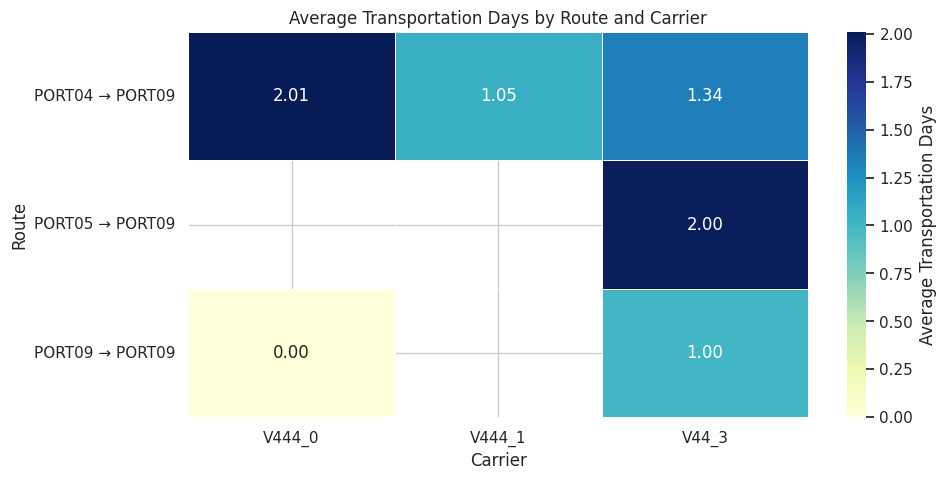

In [ ]:
route_carrier_heatmap = orders_delivery.pivot_table(
    index="route",
    columns="carrier",
    values="transport_days",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    route_carrier_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={
        "label": "Average Transportation Days"
    }
)

plt.title("Average Transportation Days by Route and Carrier")
plt.xlabel("Carrier")
plt.ylabel("Route")
plt.show()

Weight Group × Carrier Heatmap

In [ ]:
orders_delivery["weight_group"] = pd.qcut(
    orders_delivery["weight"],
    q=4,
    labels=[
        "Light",
        "Medium-Light",
        "Medium-Heavy",
        "Heavy"
    ],
    duplicates="drop"
)

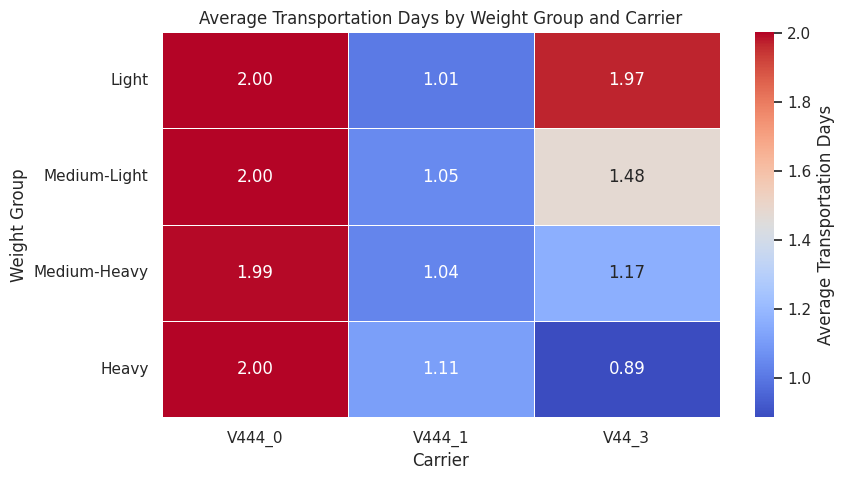

In [ ]:
weight_carrier_heatmap = orders_delivery.pivot_table(
    index="weight_group",
    columns="carrier",
    values="transport_days",
    aggfunc="mean",
    observed=False
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    weight_carrier_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={
        "label": "Average Transportation Days"
    }
)

plt.title("Average Transportation Days by Weight Group and Carrier")
plt.xlabel("Carrier")
plt.ylabel("Weight Group")
plt.show()

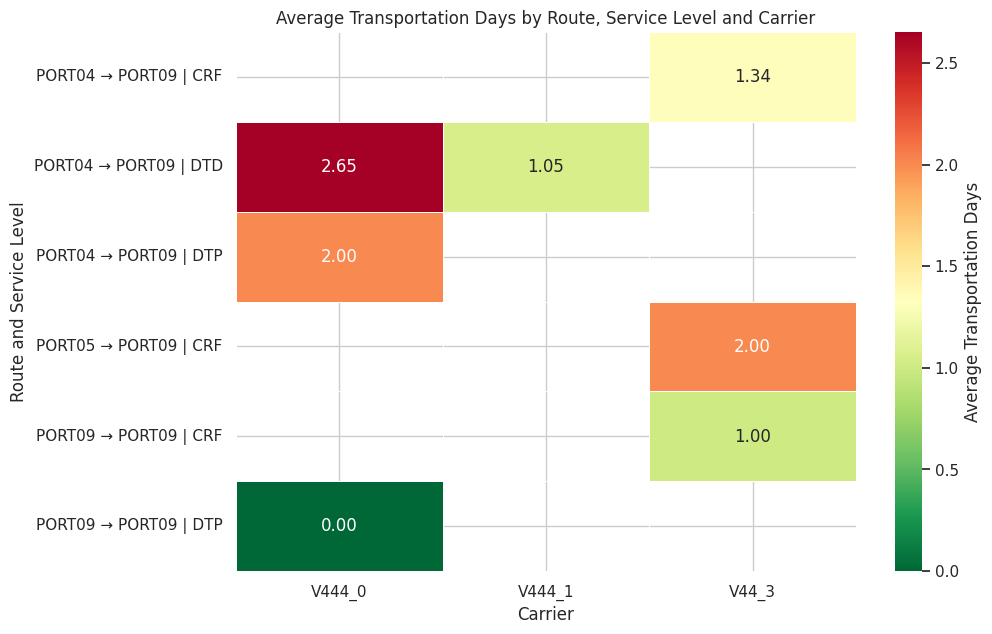

In [ ]:
orders_delivery["route_service"] = (
    orders_delivery["route"]
    + " | "
    + orders_delivery["service_level"]
)

controlled_heatmap = orders_delivery.pivot_table(
    index="route_service",
    columns="carrier",
    values="transport_days",
    aggfunc="mean"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    controlled_heatmap,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={
        "label": "Average Transportation Days"
    }
)

plt.title(
    "Average Transportation Days by Route, Service Level and Carrier"
)
plt.xlabel("Carrier")
plt.ylabel("Route and Service Level")
plt.show()

In [ ]:
dtd_same_route = orders_delivery[
    (orders_delivery["route"] == "PORT04 → PORT09")
    & (orders_delivery["service_level"] == "DTD")
    & (orders_delivery["weight"] > 0)
].copy()

dtd_same_route["weight_group"] = pd.qcut(
    dtd_same_route["weight"],
    q=4,
    labels=[
        "Light",
        "Medium-Light",
        "Medium-Heavy",
        "Heavy"
    ],
    duplicates="drop"
)

dtd_weight_carrier = (
    dtd_same_route
    .groupby(
        ["weight_group", "carrier"],
        observed=False
    )
    .agg(
        total_orders=("order_id", "nunique"),
        average_weight=("weight", "mean"),
        average_transport_days=("transport_days", "mean")
    )
    .reset_index()
)

# 移除沒有訂單的組合
dtd_weight_carrier = dtd_weight_carrier[
    dtd_weight_carrier["total_orders"] > 0
]

display(dtd_weight_carrier.round(2))

,weight_group,carrier,total_orders,average_weight,average_transport_days
1,Light,V444_1,536,0.84,1.01
2,Medium-Light,V444_0,12,3.93,2.42
3,Medium-Light,V444_1,524,3.40,1.05
4,Medium-Heavy,V444_0,23,8.30,2.83
5,Medium-Heavy,V444_1,512,8.95,1.04
6,Heavy,V444_0,11,84.81,2.55
7,Heavy,V444_1,525,37.63,1.12


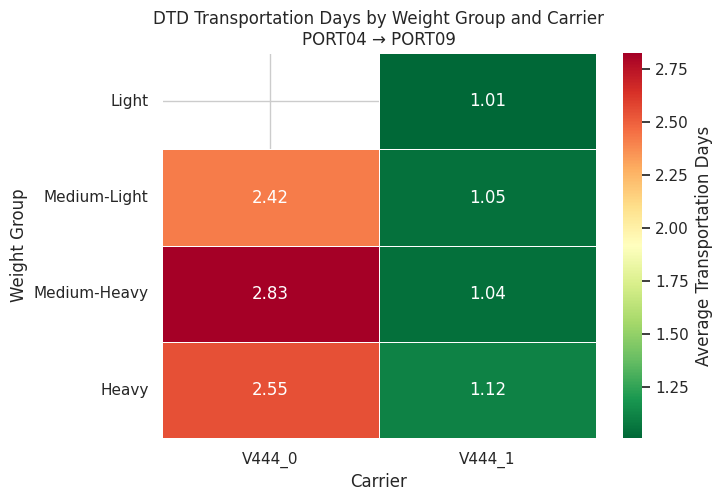

In [ ]:
dtd_weight_heatmap = dtd_same_route.pivot_table(
    index="weight_group",
    columns="carrier",
    values="transport_days",
    aggfunc="mean",
    observed=False
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    dtd_weight_heatmap,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={"label": "Average Transportation Days"}
)

plt.title(
    "DTD Transportation Days by Weight Group and Carrier\n"
    "PORT04 → PORT09"
)
plt.xlabel("Carrier")
plt.ylabel("Weight Group")
plt.show()

In [ ]:
dtd_weight_count = dtd_same_route.pivot_table(
    index="weight_group",
    columns="carrier",
    values="order_id",
    aggfunc="nunique",
    fill_value=0,
    observed=False
)

display(dtd_weight_count)

carrier,V444_0,V444_1
weight_group,,
Light,0,536
Medium-Light,12,524
Medium-Heavy,23,512
Heavy,11,525


#### 控制產品

In [ ]:
dtd_same_route = orders_delivery[
    (orders_delivery["route"] == "PORT04 → PORT09")
    & (orders_delivery["service_level"] == "DTD")
].copy()

carrier_product_summary = (
    dtd_same_route
    .groupby("carrier")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
        product_list=(
            "product_id",
            lambda values: ", ".join(
                sorted(values.astype(str).unique())
            )
        )
    )
    .reset_index()
)

display(carrier_product_summary)

,carrier,total_orders,unique_products,product_list
0,V444_0,46,3,"1663347, 1671426, 1692333"
1,V444_1,2097,214,"1644308, 1650715, 1650904, 1650905, 1651298, 1..."


In [ ]:
v444_0_products = set(
    dtd_same_route.loc[
        dtd_same_route["carrier"] == "V444_0",
        "product_id"
    ]
)

v444_1_products = set(
    dtd_same_route.loc[
        dtd_same_route["carrier"] == "V444_1",
        "product_id"
    ]
)

shared_products = (
    v444_0_products
    & v444_1_products
)

print("V444_0 products:", len(v444_0_products))
print("V444_1 products:", len(v444_1_products))
print("Shared products:", len(shared_products))
print("Shared product IDs:", sorted(shared_products))

V444_0 products: 3
V444_1 products: 214
Shared products: 1
Shared product IDs: ['1692333']


In [ ]:
shared_product_orders = dtd_same_route[
    dtd_same_route["product_id"].isin(
        shared_products
    )
]

product_carrier_comparison = (
    shared_product_orders
    .groupby([
        "product_id",
        "carrier"
    ])
    .agg(
        total_orders=("order_id", "nunique"),
        average_transport_days=("transport_days", "mean"),
        median_transport_days=("transport_days", "median"),
        average_weight=("weight", "mean")
    )
    .reset_index()
)

display(
    product_carrier_comparison
    .sort_values([
        "product_id",
        "carrier"
    ])
    .round(2)
)

,product_id,carrier,total_orders,average_transport_days,median_transport_days,average_weight
0,1692333,V444_0,11,2.0,2.0,4.9
1,1692333,V444_1,2,1.0,1.0,1.5


In [ ]:
comparable_products = (
    product_carrier_comparison
    .groupby("product_id")
    .filter(
        lambda group:
        group["carrier"].nunique() > 1
    )
)

display(
    comparable_products
    .sort_values([
        "product_id",
        "average_transport_days"
    ])
    .round(2)
)

,product_id,carrier,total_orders,average_transport_days,median_transport_days,average_weight
1,1692333,V444_1,2,1.0,1.0,1.5
0,1692333,V444_0,11,2.0,2.0,4.9


- 在相同的 PORT04 → PORT09 路線與 DTD Service Level 下，只有產品 1692333 同時由兩家 Carrier 運送。
- V444_1 的 2 筆訂單平均為 1 天；V444_0 的 11 筆訂單平均為 2 天。
- 由於樣本數太少且不平衡，無法據此可靠判斷 Carrier 的時間差異。
- 因此，目前資料不足以完整控制 Product ID 對比較結果的影響。

### 配送效率與承運商分析總結
#### 承運商使用分布

- V444_0 共處理 **6,264 筆訂單（67.98%）**，是使用量最高的承運商。
- V444_1 處理 **2,097 筆（22.76%）**，V44_3 則處理 **854 筆（9.27%）**。
- 各承運商的整體平均設定運輸時間為：
  - **V444_1：1.05 天**
  - **V44_3：1.29 天**
  - **V444_0：2.00 天**
- 由於不同 Carrier 負責的路線及 Service Level 不同，因此不能將整體平均天數直接視為承運商績效排名。
- 67.98% 的訂單集中於 V444_0，可能形成承運商依賴風險。

#### 路線分析

- PORT04 → PORT09 是最主要的配送路線，共處理 **9,041 筆訂單（98.11%）**。
- PORT09 → PORT09 處理 **173 筆（1.88%）**；PORT05 → PORT09 只有 **1 筆（0.01%）**。
- 各路線的平均設定運輸時間為：
  - **PORT04 → PORT09：1.74 天**
  - **PORT09 → PORT09：0.80 天**
  - **PORT05 → PORT09：2.00 天** (只有一筆訂單，因此其平均值不具代表性。)

- 訂單高度集中在 PORT04 → PORT09，可能形成路線中斷風險；不過該路線共有三家 Carrier 可以提供服務。
- 0 天的運輸紀錄可能代表當日或不足一天的運輸。本分析保留這些紀錄，但不將其解讀為已確認的當日送達。

#### Service Level 分析

- DTD 共處理 **2,143 筆訂單（23.26%）**，整體平均運輸時間最短，為 **1.09 天**。
- CRF 共處理 **854 筆（9.27%）**，平均為 **1.29 天**。
- DTP 共處理 **6,218 筆（67.48%）**，平均為 **1.99 天**。
- 在主要路線 PORT04 → PORT09 上：
  - **DTD：1.09 天**
  - **CRF：1.34 天**
  - **DTP：2.00 天**
- 但在 PORT09 → PORT09 上，DTP 平均為 0 天，CRF 則為 1 天。
- 因此，Service Level 與運輸時間的關係會隨路線不同而改變，不能只看整體平均值。

#### Carrier 與 Service Level 的關係

- Carrier 與 Service Level 高度綁定：
  - V44_3 只處理 CRF 訂單。
  - V444_1 只處理 DTD 訂單。
  - V444_0 處理 6,218 筆 DTP 及 46 筆 DTD 訂單。
- 約 **99.27% 的 V444_0 訂單屬於 DTP**，因此其整體平均兩天主要受到 Service Level 配置影響。
- 所以不同 Carrier 的整體時間差異，不能完全歸因於承運商本身。

#### 控制路線與 Service Level 後的比較

- PORT04 → PORT09 的 DTD，是唯一同時由多家 Carrier 提供的路線—服務組合。
- 在相同條件下：
  - V444_1 處理 **2,097 筆訂單**，平均為 **1.05 天**。
  - V444_0 處理 **46 筆訂單**，平均為 **2.65 天**。
- 此結果顯示，在相同路線與 Service Level 下，V444_1 與較短的設定運輸時間有關。
- 不過兩者樣本數差距很大，而且 V444_0 的平均訂單重量較高，因此仍需謹慎解讀。

#### 控制重量後的比較

- 本分析將 PORT04 → PORT09 的 DTD 訂單分成四個重量群。
- 在 Medium-Light、Medium-Heavy 及 Heavy 三個可比較群組中，V444_1 的設定運輸時間皆短於 V444_0。
- 這表示 Carrier 之間的時間差異，並非完全由訂單重量造成。
- 然而，V444_0 只有 46 筆紀錄，且在 Light 群組中沒有資料。
- 從所有 Carrier 的結果來看，重量與運輸時間沒有一致關係，因此重量更適合在運費分析中作為成本驅動因素。

#### 控制 Product ID 後的比較

- 在相同路線與 DTD 條件下，只有產品 1692333 同時由 V444_0 和 V444_1 運送。
- V444_1 的 2 筆訂單平均為 1 天；V444_0 的 11 筆訂單平均為 2 天。
- 由於樣本數太少且不平衡，無法據此可靠比較兩家 Carrier。
- 因此，目前資料不足以完整排除 Product ID 對結果的影響。

#### 整體結論與限制

- 控制路線、Service Level 及大致重量群後，V444_1 仍與較短的設定運輸時間相關。
- 但這不能證明 V444_1 導致配送速度提升。
- `transport_days` 代表設定或預估運輸時間，而不是實際送達時間。
- 由於缺少預計送達日期及實際送達日期，無法計算準時率、實際延誤或真正的 Carrier 績效。
- 因此，本分析呈現的是變數之間的關聯與供應網路集中風險，而不是因果關係。
---
#### Carrier Distribution

- V444_0 handled **6,264 orders (67.98%)**, making it the most frequently used carrier.
- V444_1 handled **2,097 orders (22.76%)**, while V44_3 handled **854 orders (9.27%)**.
- The overall average configured transportation times were:
  - **V444_1: 1.05 days**
  - **V44_3: 1.29 days**
  - **V444_0: 2.00 days**
- However, these overall averages should not be treated as direct carrier-performance rankings because the carriers handled different routes and service levels.
- The concentration of 67.98% of orders with V444_0 may represent a potential carrier-dependency risk.

#### Route Analysis

- PORT04 → PORT09 was the dominant route, handling **9,041 orders (98.11%)**.
- PORT09 → PORT09 handled **173 orders (1.88%)**, while PORT05 → PORT09 handled only **one order (0.01%)**.
- Average configured transportation times were:
  - **PORT04 → PORT09: 1.74 days**
  - **PORT09 → PORT09: 0.80 days**
  - **PORT05 → PORT09: 2.00 days**
- The PORT05 → PORT09 result was based on only one order and was therefore not considered representative.
- The high concentration of orders on PORT04 → PORT09 represents a potential route-disruption risk, although three carriers were available on this route.
- Zero-day transportation records may represent same-day or less-than-one-day transportation. They were retained but were not interpreted as confirmed same-day delivery.

#### Service-Level Analysis

- DTD handled **2,143 orders (23.26%)** and had the shortest overall average transportation time of **1.09 days**.
- CRF handled **854 orders (9.27%)** with an average of **1.29 days**.
- DTP handled **6,218 orders (67.48%)** with an average of **1.99 days**.
- On the primary PORT04 → PORT09 route, average transportation times were:
  - **DTD: 1.09 days**
  - **CRF: 1.34 days**
  - **DTP: 2.00 days**
- However, on PORT09 → PORT09, DTP averaged 0 days while CRF averaged 1 day.
- Therefore, the relationship between service level and transportation time varied by route and should not be evaluated only through overall averages.

#### Carrier and Service-Level Interaction

- Carrier and service-level assignments were strongly associated:
  - V44_3 handled only CRF orders.
  - V444_1 handled only DTD orders.
  - V444_0 handled 6,218 DTP orders and 46 DTD orders.
- Approximately **99.27% of V444_0 orders used DTP**, meaning its overall two-day average was primarily influenced by its service-level assignment.
- Therefore, differences in overall transportation time could not be attributed solely to carrier performance.

#### Controlled Carrier Comparison

- PORT04 → PORT09 with DTD was the only route–service combination served by multiple carriers.
- Within this comparable combination:
  - V444_1 handled **2,097 orders** with an average transportation time of **1.05 days**.
  - V444_0 handled **46 orders** with an average transportation time of **2.65 days**.
- This suggests that V444_1 was associated with shorter configured transportation time under the same route and service-level conditions.
- However, the sample sizes were highly unbalanced, and V444_0 orders had a higher average weight.

#### Weight-Controlled Comparison

- Orders on PORT04 → PORT09 with DTD were divided into four weight groups.
- Within the medium-light, medium-heavy, and heavy groups, V444_1 consistently had shorter configured transportation times than V444_0.
- This suggests that the observed carrier difference was not explained solely by shipment weight.
- Nevertheless, V444_0 had only 46 observations and no observations in the light group.
- Across all carriers, shipment weight did not show a consistent relationship with transportation time. Weight is therefore more appropriate as a freight-cost driver than as a transportation-time driver.

#### Product-Controlled Comparison

- Only one product, Product 1692333, was transported by both V444_0 and V444_1 under the same route and DTD service level.
- V444_1 handled 2 orders with an average of 1 day, while V444_0 handled 11 orders with an average of 2 days.
- The sample was too small and unbalanced to support a reliable product-controlled carrier comparison.
- Therefore, product-level differences could not be fully controlled using the available data.

#### Overall Interpretation and Limitations

- V444_1 was consistently associated with shorter configured transportation time after controlling for route, service level, and broad weight groups.
- However, this result does not prove that V444_1 caused faster delivery.
- The dataset contains configured or estimated transportation days rather than actual delivery dates.
- Actual carrier performance, on-time delivery rate, and delay duration cannot be evaluated without planned and actual delivery timestamps.
- The analysis identifies associations and network concentration risks rather than causal carrier-performance differences.

---

# 7.港口與工廠配置

## 7.1 各工廠可用港口

In [ ]:
plant_port_summary = (
    plant_ports
    .groupby("plant_code")
    .agg(
        available_port_count=("port", "nunique"),
        available_ports=(
            "port",
            lambda values: ", ".join(
                sorted(values.astype(str).unique())
            )
        )
    )
    .reset_index()
)

display(plant_port_summary)

,plant_code,available_port_count,available_ports
0,PLANT01,2,"PORT01, PORT02"
1,PLANT02,1,PORT03
2,PLANT03,1,PORT04
3,PLANT04,1,PORT05
4,PLANT05,1,PORT06
5,PLANT06,1,PORT06
6,PLANT07,2,"PORT01, PORT02"
7,PLANT08,1,PORT04
8,PLANT09,1,PORT04
9,PLANT10,2,"PORT01, PORT02"


檢查歷史訂單港口是否符合目前配置

In [ ]:
port_validation = orders.merge(
    plant_ports.rename(columns={"port": "origin_port"}),
    on=["plant_code", "origin_port"],
    how="left",
    indicator=True,
    validate="many_to_one"
)

port_validation["port_status"] = (
    port_validation["_merge"]
    .map({
        "both": "Current Port Match",
        "left_only": "Not in Current Configuration"
    })
)

port_validation["port_status"].value_counts()

,count
port_status,
Current Port Match,9215


結論：9,215 筆訂單全數符合目前 plant–port 配置（100%）。

In [ ]:
port_status_summary = (
    port_validation
    .groupby("port_status")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum")
    )
    .reset_index()
)

port_status_summary["order_share_pct"] = (
    port_status_summary["total_orders"]
    / port_status_summary["total_orders"].sum()
    * 100
)

display(port_status_summary.round(2))

,port_status,total_orders,total_units,total_weight,order_share_pct
0,Current Port Match,9215,29513315,183117.6,100.0


## 7.2 各港口訂單量

In [ ]:
port_demand = (
    orders
    .groupby("origin_port")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("unit_quantity", "sum"),
        total_weight=("weight", "sum"),
        unique_plants=("plant_code", "nunique"),
        unique_customers=("customer", "nunique")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

port_demand["order_share_pct"] = (
    port_demand["total_orders"]
    / port_demand["total_orders"].sum()
    * 100
)

display(port_demand.round(2))

,origin_port,total_orders,total_units,total_weight,unique_plants,unique_customers,order_share_pct
0,PORT04,9041,29267834,150947.49,5,45,98.11
2,PORT09,173,245133,32168.01,1,3,1.88
1,PORT05,1,348,2.10,1,1,0.01


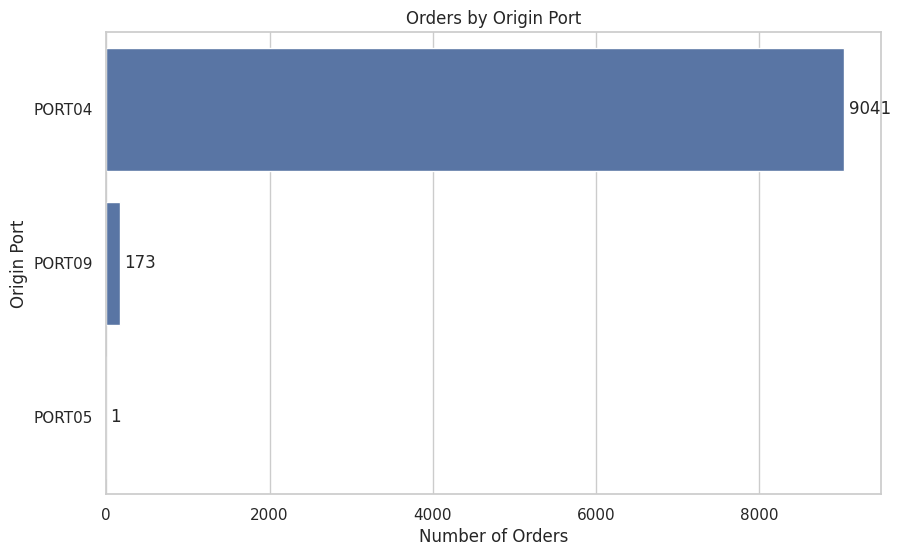

In [ ]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=port_demand,
    x="total_orders",
    y="origin_port",
    color="#4C72B0"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Orders by Origin Port")
plt.xlabel("Number of Orders")
plt.ylabel("Origin Port")
plt.show()

## 7.3 各工廠可用港口 vs. 歷史使用港口

In [ ]:
historical_plant_ports = (
    orders.groupby("plant_code")["origin_port"]
    .agg(
        lambda values: ", ".join(
            sorted(values.astype(str).unique())
        )
    )
    .reset_index(name="historical_ports")
)

plant_port_options = plant_port_summary.merge(
    historical_plant_ports,
    on="plant_code",
    how="left"
)

display(plant_port_options)

,plant_code,available_port_count,available_ports,historical_ports
0,PLANT01,2,"PORT01, PORT02",<NA>
1,PLANT02,1,PORT03,<NA>
2,PLANT03,1,PORT04,PORT04
3,PLANT04,1,PORT05,PORT05
4,PLANT05,1,PORT06,<NA>
5,PLANT06,1,PORT06,<NA>
6,PLANT07,2,"PORT01, PORT02",<NA>
7,PLANT08,1,PORT04,PORT04
8,PLANT09,1,PORT04,PORT04
9,PLANT10,2,"PORT01, PORT02",<NA>


### Findings  
### 工廠—港口分析結論

#### English

- All 9,215 historical orders matched the current plant–port configuration, resulting in a 100% configuration match rate.
- PORT04 handled 9,041 orders, representing 98.11% of all orders and indicating a high level of port concentration.
- PORT09 handled 173 orders (1.88%), while PORT05 handled only one order (0.01%).
- The high dependency on PORT04 may represent a network concentration risk if the port experiences congestion or disruption.
- However, port overload cannot be confirmed because port-capacity data is not available.
- Plants with historical orders currently have only one configured origin port. Therefore, no direct alternative origin ports are available for these orders under the current plant–port configuration.
- Plants with multiple available ports did not process orders in this historical dataset. Using their ports would require a broader plant or product reallocation analysis.

#### 中文

- 全部 9,215 筆歷史訂單使用的工廠—起點港口組合，皆符合目前的港口配置，匹配率為 100%。
- PORT04 共處理 9,041 筆訂單，占全部訂單的 98.11%，顯示訂單高度集中於單一港口。建議評估備援港口（但無港口產能資料，無法確認是否壅塞）。
- PORT09 處理 173 筆訂單，占 1.88%；PORT05 僅處理 1 筆訂單，占 0.01%。
- 供應網路高度依賴 PORT04，因此若該港口發生壅塞或中斷，可能影響大部分訂單。
- 由於資料中沒有港口容量，因此無法判斷 PORT04 是否已經超載，只能辨識其集中風險。
- 有歷史訂單的工廠目前都只有一個配置港口，因此在現有工廠—港口限制下，沒有直接可用的替代起點港口。
- 具有多個港口的工廠在這批歷史資料中沒有處理訂單；若要使用這些港口，還需要進一步評估產品供應能力、工廠產能及訂單重新分配的可行性。

# 8.運費估算與成本分析 Freight Rate and Cost Analysis

## 8.1 費率表概況

In [ ]:
freight_rates_analysis = freight_rates.copy()

freight_rates_analysis["route"] = (
    freight_rates_analysis["origin_port"]
    + " → "
    + freight_rates_analysis["destination_port"]
)

freight_rate_summary = (
    freight_rates_analysis
    .groupby([
        "carrier",
        "transport_mode",
        "service_level"
    ])
    .agg(
        rate_records=("rate", "size"),
        unique_routes=("route", "nunique"),
        average_rate=("rate", "mean"),
        median_rate=("rate", "median"),
        min_rate=("rate", "min"),
        max_rate=("rate", "max"),
        average_min_cost=("min_cost", "mean"),
        average_transport_days=("transport_days", "mean")
    )
    .reset_index()
)

display(freight_rate_summary.round(2))

,carrier,transport_mode,service_level,rate_records,unique_routes,average_rate,median_rate,min_rate,max_rate,average_min_cost,average_transport_days
0,V444_0,AIR,DTD,15,2,0.07,0.06,0.05,0.10,10.25,3.00
1,V444_0,AIR,DTP,10,1,0.04,0.04,0.04,0.05,1.50,2.50
2,V444_0,GROUND,DTD,11,2,12.65,13.20,7.20,17.32,29.47,0.91
3,V444_0,GROUND,DTP,1,1,12.28,12.28,12.28,12.28,31.28,0.00
4,V444_1,AIR,DTD,292,5,1.47,0.74,0.07,6.62,15.34,2.00
5,V444_2,AIR,DTD,55,5,0.16,0.19,0.08,0.28,17.61,4.73
6,V444_2,AIR,DTP,20,4,0.13,0.15,0.07,0.19,13.43,4.50
7,V444_4,AIR,DTD,755,5,4.00,3.11,0.10,18.96,6.77,1.60
8,V444_4,AIR,DTP,151,1,2.75,2.29,0.10,7.16,6.06,2.00
9,V444_5,AIR,DTD,35,3,0.12,0.09,0.07,0.31,12.02,2.43


## 8.2 歷史訂單運費估算

- 配對條件：承運商 + 起點港 + 終點港 + Service Level + 運輸天數 + 重量區間；運費 = max(重量 × 費率, 最低收費)。

In [ ]:
order_rate_candidates = orders.merge(
    freight_rates,
    on=[
        "carrier",
        "origin_port",
        "destination_port",
        "service_level",
         "transport_days"
    ],
    how="left",
    suffixes=("_order", "_rate")
)

matched_order_rates = order_rate_candidates[
    (
        order_rate_candidates["weight"]
        >= order_rate_candidates["min_weight"]
    )
    &
    (
        order_rate_candidates["weight"]
        <= order_rate_candidates["max_weight"]
    )
].copy()

In [ ]:
match_count = (
    matched_order_rates
    .groupby("order_id")
    .size()
)

print("Matched orders:")
print(match_count.shape[0])

print("\nOrders with more than one rate match:")
print((match_count > 1).sum())

print("\nOrders without a rate match:")
print(
    orders["order_id"].nunique()
    - match_count.shape[0]
)

Matched orders:
6991

Orders with more than one rate match:
727

Orders without a rate match:
2224


In [ ]:
matched_order_rates["variable_cost"] = (
    matched_order_rates["weight"]
    * matched_order_rates["rate"]
)

matched_order_rates["estimated_freight_cost"] = (
    matched_order_rates[[
        "variable_cost",
        "min_cost"
    ]]
    .max(axis=1)
)

## 8.3 重複配對與最低成本情境

同一筆訂單可能對應到多筆費率。目標包括成本最佳化，因此每筆訂單取預估運費最低者，定義為 lowest-cost scenario。

### 檢查重複配對狀況

In [ ]:
match_count = (
    matched_order_rates
    .groupby("order_id")
    .size()
    .reset_index(name="rate_match_count")
)

match_count["rate_match_count"].value_counts().sort_index()

,count
rate_match_count,
1,6264
2,727


In [ ]:
match_count.sort_values(
    "rate_match_count",
    ascending=False
).head(10)

,order_id,rate_match_count
1005,1447169055.7,2
5473,1447355490.7,2
5474,1447355493.7,2
3264,1447261807.7,2
3263,1447261788.7,2
6100,1447382049.7,2
6101,1447382051.7,2
5478,1447355980.7,2
5479,1447355993.7,2
5480,1447355994.7,2


In [ ]:
sample_order_id = match_count.loc[
    match_count["rate_match_count"] > 1,
    "order_id"
].iloc[0]

print(sample_order_id)

1447139280.7


In [ ]:
display(
    matched_order_rates.loc[
        matched_order_rates["order_id"] == sample_order_id,
        [
            "order_id",
            "weight",
            "carrier",
            "origin_port",
            "destination_port",
            "service_level",
            "min_weight",
            "max_weight",
            "rate",
            "min_cost",
            "transport_mode",
            "carrier_type"
        ]
    ]
)

,order_id,weight,carrier,origin_port,destination_port,service_level,min_weight,max_weight,rate,min_cost,transport_mode,carrier_type
60200,1447139280.7,1.225287,V444_1,PORT04,PORT09,DTD,1.01,1.5,0.3192,1.3192,AIR,V888888883_1
60210,1447139280.7,1.225287,V444_1,PORT04,PORT09,DTD,1.01,1.5,0.4824,1.4824,AIR,V888888883_1


### 範例：檢視另一筆重複配對的訂單

In [ ]:
duplicate_order_id = match_count.loc[
    match_count["rate_match_count"] == 2,
    "order_id"
].iloc[2]

display(
    matched_order_rates.loc[
        matched_order_rates["order_id"] == duplicate_order_id,
        [
            "order_id",
            "weight",
            "carrier",
            "origin_port",
            "destination_port",
            "service_level",
            "transport_days",
            "min_weight",
            "max_weight",
            "transport_mode",
            "carrier_type",
            "rate",
            "min_cost"
        ]
    ]
)

,order_id,weight,carrier,origin_port,destination_port,service_level,transport_days,min_weight,max_weight,transport_mode,carrier_type,rate,min_cost
35941,1447139823.7,1.78846,V444_1,PORT04,PORT09,DTD,1,1.51,2.0,AIR,V888888883_1,0.3804,1.3804
35951,1447139823.7,1.78846,V444_1,PORT04,PORT09,DTD,1,1.51,2.0,AIR,V888888883_1,0.5252,1.5252


### 每筆訂單取最低成本方案

In [ ]:
lowest_cost_orders = (
    matched_order_rates
    .sort_values(
        ["order_id", "estimated_freight_cost"]
    )
    .drop_duplicates(
        subset="order_id",
        keep="first"
    )
    .copy()
)

In [ ]:
print("Rows:", len(lowest_cost_orders))
print(
    "Unique orders:",
    lowest_cost_orders["order_id"].nunique()
)
print(
    "Duplicate orders:",
    lowest_cost_orders["order_id"].duplicated().sum()
)

Rows: 6991
Unique orders: 6991
Duplicate orders: 0


### 驗證範例訂單是否選到較低成本

In [ ]:
selected_order = lowest_cost_orders.loc[
    lowest_cost_orders["order_id"] == sample_order_id,
    [
        "order_id",
        "weight",
        "carrier",
        "origin_port",
        "destination_port",
        "service_level",
        "transport_days",
        "min_weight",
        "max_weight",
        "rate",
        "min_cost",
        "variable_cost",
        "estimated_freight_cost"
    ]
]

display(selected_order)

,order_id,weight,carrier,origin_port,destination_port,service_level,transport_days,min_weight,max_weight,rate,min_cost,variable_cost,estimated_freight_cost
60200,1447139280.7,1.225287,V444_1,PORT04,PORT09,DTD,1,1.01,1.5,0.3192,1.3192,0.391112,1.3192


### 成本範圍與潛在節省

建立每筆訂單的最低與最高候選成本：

In [ ]:
order_cost_scenarios = (
    matched_order_rates
    .groupby("order_id")
    .agg(
        rate_match_count=("rate", "size"),
        lowest_estimated_cost=(
            "estimated_freight_cost", "min"
        ),
        highest_estimated_cost=(
            "estimated_freight_cost", "max"
        )
    )
    .reset_index()
)

order_cost_scenarios["potential_savings"] = (
    order_cost_scenarios["highest_estimated_cost"]
    - order_cost_scenarios["lowest_estimated_cost"]
)

### 有兩種費率的訂單（727 筆）：最低與最高成本

In [ ]:
display(
    order_cost_scenarios[
        order_cost_scenarios["rate_match_count"] > 1
    ]
    .sort_values("potential_savings", ascending=False)
    .head(10)
)

,order_id,rate_match_count,lowest_estimated_cost,highest_estimated_cost,potential_savings
6131,1447383130.7,2,31.267200,33.227200,1.960000
6221,1447387440.7,2,32.274082,33.598147,1.324065
6137,1447383145.7,2,7.804400,9.088400,1.284000
6129,1447383128.7,2,7.804400,9.088400,1.284000
6619,1447405864.7,2,7.804400,9.088400,1.284000
118,1447145082.7,2,7.804400,9.088400,1.284000
6150,1447384244.7,2,7.804400,9.088400,1.284000
6138,1447383147.7,2,7.804400,9.088400,1.284000
5574,1447360901.7,2,7.804400,9.088400,1.284000
572,1447158912.7,2,7.804400,9.088400,1.284000


In [ ]:
ambiguous_orders = order_cost_scenarios[
    order_cost_scenarios["rate_match_count"] > 1
]

print(
    "Potential savings under the lowest-cost scenario:",
    round(ambiguous_orders["potential_savings"].sum(), 2)
)

Potential savings under the lowest-cost scenario: 175.98


## 8.4 費率覆蓋率（Rate Coverage）

費率表並未涵蓋所有承運商，因此先確認歷史訂單中有多少筆能成功估算運費。

### 整體配對率

In [ ]:
total_orders = orders["order_id"].nunique()
matched_orders = lowest_cost_orders["order_id"].nunique()
unmatched_orders_count = total_orders - matched_orders

match_rate = matched_orders / total_orders * 100

rate_match_summary = pd.DataFrame({
    "metric": [
        "Total orders",
        "Matched orders",
        "Unmatched orders",
        "Match rate"
    ],
    "value": [
        total_orders,
        matched_orders,
        unmatched_orders_count,
        f"{match_rate:.2f}%"
    ]
})

display(rate_match_summary)

,metric,value
0,Total orders,9215
1,Matched orders,6991
2,Unmatched orders,2224
3,Match rate,75.87%


### 費率表中的承運商紀錄數

In [ ]:
display(
    freight_rates["carrier"]
    .value_counts()
    .rename_axis("carrier")
    .reset_index(name="rate_records")
)

,carrier,rate_records
0,V444_4,906
1,V444_1,292
2,V444_8,100
3,V444_5,83
4,V444_2,75
5,V444_6,38
6,V444_0,37
7,V444_9,5
8,V444_7,1


### 各承運商的費率覆蓋率

In [ ]:
carrier_rate_coverage = (
    orders.groupby("carrier")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
    .merge(
        lowest_cost_orders
        .groupby("carrier")
        .agg(current_rate_matched=("order_id", "nunique"))
        .reset_index(),
        on="carrier",
        how="left"
    )
)

carrier_rate_coverage["current_rate_matched"] = (
    carrier_rate_coverage["current_rate_matched"]
    .fillna(0)
    .astype(int)
)

carrier_rate_coverage["current_match_rate_pct"] = (
    carrier_rate_coverage["current_rate_matched"]
    / carrier_rate_coverage["total_orders"]
    * 100
)

display(carrier_rate_coverage.round(2))

,carrier,total_orders,current_rate_matched,current_match_rate_pct
0,V444_0,6264,6264,100.00
1,V444_1,2097,727,34.67
2,V44_3,854,0,0.00


在比較預估運費之前，需要先確認 Freight Rate 表對各承運商歷史訂單的涵蓋程度。訂單的承運商、起點、目的地、服務等級、運輸天數及重量區間皆符合費率紀錄時，才能成功估算運費。

此分析比較各承運商的歷史訂單總數與成功配對其自身費率的訂單數。若費率配對率偏低，代表該承運商的成本估算只涵蓋部分訂單，不能視為完整的歷史運費支出。

V444_0 的 6,264 筆訂單皆成功配對費率，覆蓋率為 100%；V444_1 的 2,097 筆訂單中，只有 727 筆成功配對，覆蓋率為 34.67%；V44_3 的 854 筆訂單則完全無法配對，因為 Freight Rate 表中沒有該承運商的費率紀錄。

整體而言，原承運商費率涵蓋了 9,215 筆訂單中的 6,991 筆，覆蓋率為 75.87%。因此，初始運費估算僅代表成功配對費率的訂單，不能解讀為全部歷史訂單的完整運費。

## 8.5 承運商與路線成本比較

以下僅涵蓋「以原承運商費率成功配對」的訂單（lowest-cost scenario）。

### 各承運商成本

In [ ]:
carrier_cost_summary = (
    lowest_cost_orders
    .groupby("carrier")
    .agg(
        total_orders=("order_id", "nunique"),
        total_weight=("weight", "sum"),
        total_estimated_freight_cost=(
            "estimated_freight_cost", "sum"
        ),
        average_cost_per_order=(
            "estimated_freight_cost", "mean"
        ),
        average_rate=("rate", "mean"),
        average_transport_days=(
            "transport_days", "mean"
        )
    )
    .reset_index()
)

carrier_cost_summary["estimated_cost_per_weight"] = (
    carrier_cost_summary["total_estimated_freight_cost"]
    / carrier_cost_summary["total_weight"]
)

display(carrier_cost_summary.round(2))

,carrier,total_orders,total_weight,total_estimated_freight_cost,average_cost_per_order,average_rate,average_transport_days,estimated_cost_per_weight
0,V444_0,6264,121440.44,68094.44,10.87,0.11,2.00,0.56
1,V444_1,727,7434.34,1473.79,2.03,0.28,1.03,0.20


### 各路線成本

In [ ]:
route_cost_summary = (
    lowest_cost_orders
    .groupby([
        "origin_port",
        "destination_port"
    ])
    .agg(
        total_orders=("order_id", "nunique"),
        total_weight=("weight", "sum"),
        total_estimated_freight_cost=(
            "estimated_freight_cost", "sum"
        ),
        average_cost_per_order=(
            "estimated_freight_cost", "mean"
        ),
        average_transport_days=(
            "transport_days", "mean"
        )
    )
    .reset_index()
)

route_cost_summary["route"] = (
    route_cost_summary["origin_port"]
    + " → "
    + route_cost_summary["destination_port"]
)

display(
    route_cost_summary
    .sort_values(
        "total_estimated_freight_cost",
        ascending=False
    )
    .head(10)
    .round(2)
)

,origin_port,destination_port,total_orders,total_weight,total_estimated_freight_cost,average_cost_per_order,average_transport_days,route
1,PORT09,PORT09,34,4553.28,55981.16,1646.50,0.00,PORT09 → PORT09
0,PORT04,PORT09,6957,124321.50,13587.07,1.95,1.91,PORT04 → PORT09


## 8.6 預估總運費（原承運商費率）

預測歷史訂單的總運費
成功配對的 6,991 筆訂單，不包含未配對的 2,224 筆

In [ ]:
lowest_cost_total = (
    lowest_cost_orders["estimated_freight_cost"].sum()
)

print(
    f"成功配對的6991筆訂單總成本 Lowest-cost scenario total: {lowest_cost_total:,.2f}"
)

成功配對的6991筆訂單總成本 Lowest-cost scenario total: 69,568.23


### 小結：成功配對訂單的預估運費

6,991 筆成功配對費率的訂單，其最低預估運費合計為 69,568.23，
其中包含 6,264 筆 V444_0 訂單及 727 筆 V444_1 訂單，未包含
2,224 筆無法配對費率的訂單。

若同一筆訂單在原承運商下符合多筆費率，則選擇最低預估成本。
因此，此結果代表原承運商不變下的最低成本情境，而非完整的
歷史實際運費。

## 8.7 未配對訂單診斷

以原承運商費率仍無法配對的訂單，先檢視數量與樣本，再檢查配對條件找出原因。

### 未配對訂單數與樣本

In [ ]:
matched_order_ids = matched_order_rates["order_id"].unique()

unmatched_orders = orders[
    ~orders["order_id"].isin(matched_order_ids)
].copy()

print("Unmatched orders:", len(unmatched_orders))

Unmatched orders: 2224


In [ ]:
unmatched_sample = unmatched_orders.sample(
    n=10,
    random_state=42
)

display(
    unmatched_sample

)

,order_id,order_date,origin_port,carrier,transport_days,service_level,ship_ahead_day_count,ship_late_day_count,customer,product_id,plant_code,destination_port,unit_quantity,weight,weight_valid
96,1447296451.7,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1697317,PLANT16,PORT09,1222,164.560000,True
7920,1447318271.7,2013-05-26,PORT04,V444_1,1,DTD,0,0,V5555555_22,1692948,PLANT03,PORT09,1655,5.951940,True
8831,1447268288.7,2013-05-26,PORT04,V444_1,1,DTD,5,0,V55555555555555_8,1688629,PLANT03,PORT09,481,18.936531,True
8823,1447360798.7,2013-05-26,PORT04,V444_1,1,DTD,5,0,V55555555555555_8,1688629,PLANT03,PORT09,297,4.484133,True
7124,1447365202.7,2013-05-26,PORT04,V444_1,2,DTD,5,0,V55555555555555_8,1657013,PLANT12,PORT09,416,29.000000,True
707,1447182882.7,2013-05-26,PORT04,V44_3,0,CRF,3,0,V55555555_32,1699553,PLANT03,PORT09,1172,3.481718,True
7719,1447232773.7,2013-05-26,PORT04,V444_1,1,DTD,0,0,V5555555_22,1644308,PLANT03,PORT09,380,4.298521,True
290,1447377331.7,2013-05-26,PORT04,V44_3,0,CRF,0,0,V555555555555555_29,1699567,PLANT03,PORT09,10266,8.218128,True
8814,1447159998.7,2013-05-26,PORT04,V444_1,1,DTD,5,0,V55555555555555_8,1688629,PLANT03,PORT09,469,16.936531,True
8479,1447243416.7,2013-05-26,PORT04,V444_1,1,DTD,5,0,V55555555555555_8,1693747,PLANT03,PORT09,524,28.860000,True


### 未配對原因分析

In [ ]:
import numpy as np
import pandas as pd

# 1. Find orders without a matched freight rate
matched_order_ids = matched_order_rates["order_id"].unique()

unmatched_orders = orders[
    ~orders["order_id"].isin(matched_order_ids)
].copy()

print("Unmatched orders:", unmatched_orders["order_id"].nunique())


# 2. Match them with rates using route and service information
unmatched_diagnosis = unmatched_orders.merge(
    freight_rates,
    on=[
        "carrier",
        "origin_port",
        "destination_port",
        "service_level"
    ],
    how="left",
    suffixes=("_order", "_rate")
)


# 3. Check each matching condition
unmatched_diagnosis["route_rate_exists"] = (
    unmatched_diagnosis["rate"].notna()
)

unmatched_diagnosis["same_transport_days"] = (
    unmatched_diagnosis["route_rate_exists"]
    &
    (
        unmatched_diagnosis["transport_days_order"]
        == unmatched_diagnosis["transport_days_rate"]
    )
)

unmatched_diagnosis["valid_weight_bracket"] = (
    unmatched_diagnosis["same_transport_days"]
    &
    (
        unmatched_diagnosis["weight"]
        >= unmatched_diagnosis["min_weight"]
    )
    &
    (
        unmatched_diagnosis["weight"]
        <= unmatched_diagnosis["max_weight"]
    )
)


# 4. Summarize checks at the order level
order_diagnosis = (
    unmatched_diagnosis
    .groupby("order_id")
    .agg(
        route_rate_exists=("route_rate_exists", "any"),
        same_transport_days=("same_transport_days", "any"),
        valid_weight_bracket=("valid_weight_bracket", "any")
    )
    .reset_index()
)


# 5. Assign one unmatched reason to each order
order_diagnosis["unmatched_reason"] = np.select(
    [
        ~order_diagnosis["route_rate_exists"],

        (
            order_diagnosis["route_rate_exists"]
            & ~order_diagnosis["same_transport_days"]
        ),

        (
            order_diagnosis["same_transport_days"]
            & ~order_diagnosis["valid_weight_bracket"]
        )
    ],
    [
        "No matching route/service rate",
        "Transport days mismatch",
        "Weight outside rate bracket"
    ],
    default="Other"
)


# 6. Create summary
unmatched_reason_summary = (
    order_diagnosis["unmatched_reason"]
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="orders")
)

unmatched_reason_summary["percentage"] = (
    unmatched_reason_summary["orders"]
    / order_diagnosis["order_id"].nunique()
    * 100
)

display(unmatched_reason_summary.round(2))

Unmatched orders: 2224


,reason,orders,percentage
0,Weight outside rate bracket,1370,61.6
1,No matching route/service rate,854,38.4


## 8.8 替代承運商情境（Alternative Carrier）

針對未配對訂單，改用其他承運商的費率配對（條件：相同路線、Service Level、運輸天數，且重量落在費率區間），並取最低成本方案。

> 此為情境假設：需另行確認替代承運商能否承接相同的服務。

### 尋找每筆訂單可用的替代承運商

In [ ]:
alternative_candidates = orders.merge(
    freight_rates,
    on=[
        "origin_port",
        "destination_port",
        "service_level",
        "transport_days"
    ],
    how="left",
    suffixes=("_current", "_alternative")
)

# 保留重量落在費率區間內的方案
alternative_candidates = alternative_candidates[
    alternative_candidates["weight"].between(
        alternative_candidates["min_weight"],
        alternative_candidates["max_weight"]
    )
].copy()

print("可找到候選費率的訂單數：")
print(alternative_candidates["order_id"].nunique())

display(alternative_candidates.head())

可找到候選費率的訂單數：
8344


,order_id,order_date,origin_port,carrier_current,transport_days,service_level,ship_ahead_day_count,ship_late_day_count,customer,product_id,...,unit_quantity,weight,weight_valid,carrier_alternative,min_weight,max_weight,min_cost,rate,transport_mode,carrier_type
854,1447385217.7,2013-05-26,PORT09,V444_0,0,DTP,0,0,V55555_4,1692724,...,332,1.023143,True,V444_5,0.0,5000.0,31.2784,20.2784,GROUND,V88888888_0
855,1447385217.7,2013-05-26,PORT09,V444_0,0,DTP,0,0,V55555_4,1692724,...,332,1.023143,True,V444_0,0.0,5000.0,31.2784,12.2784,GROUND,V88888888_0
856,1447337778.7,2013-05-26,PORT09,V444_0,0,DTP,0,0,V55555_4,1692724,...,358,0.613886,True,V444_5,0.0,5000.0,31.2784,20.2784,GROUND,V88888888_0
857,1447337778.7,2013-05-26,PORT09,V444_0,0,DTP,0,0,V55555_4,1692724,...,358,0.613886,True,V444_0,0.0,5000.0,31.2784,12.2784,GROUND,V88888888_0
858,1447406947.7,2013-05-26,PORT09,V444_0,0,DTP,3,0,V555555_6,1692722,...,409,37.041956,True,V444_5,0.0,5000.0,31.2784,20.2784,GROUND,V88888888_0


### 只替未配對訂單尋找替代承運商

In [ ]:
unmatched_alternative_candidates = unmatched_orders.merge(
    freight_rates,
    on=[
        "origin_port",
        "destination_port",
        "service_level",
        "transport_days"
    ],
    how="left",
    suffixes=("_current", "_alternative")
)

In [ ]:
unmatched_alternative_candidates = (
    unmatched_alternative_candidates[
        unmatched_alternative_candidates["weight"].between(
            unmatched_alternative_candidates["min_weight"],
            unmatched_alternative_candidates["max_weight"]
        )
    ]
    .copy()
)

unmatched_alternative_candidates["variable_cost"] = (
    unmatched_alternative_candidates["weight"]
    * unmatched_alternative_candidates["rate"]
)

unmatched_alternative_candidates["estimated_freight_cost"] = (
    unmatched_alternative_candidates[
        ["variable_cost", "min_cost"]
    ].max(axis=1)
)

print(
    "找到替代承運商的訂單數：",
    unmatched_alternative_candidates["order_id"].nunique()
)

找到替代承運商的訂單數： 1353


### 每筆訂單選最低成本方案

In [ ]:
best_alternative_for_unmatched = (
    unmatched_alternative_candidates
    .sort_values(["order_id", "estimated_freight_cost"])
    .drop_duplicates(subset="order_id", keep="first")
    .copy()
)

print(
    "找到最低成本替代方案的訂單數：",
    best_alternative_for_unmatched["order_id"].nunique()
)

display(
    best_alternative_for_unmatched[[
        "order_id",
        "carrier_current",
        "carrier_alternative",
        "origin_port",
        "destination_port",
        "service_level",
        "transport_days",
        "weight",
        "estimated_freight_cost"
    ]].head(10)
)

找到最低成本替代方案的訂單數： 1353


,order_id,carrier_current,carrier_alternative,origin_port,destination_port,service_level,transport_days,weight,estimated_freight_cost
109671,1447137127.7,V444_1,V444_4,PORT04,PORT09,DTD,1,48.680000,175.481664
110447,1447137128.7,V444_1,V444_4,PORT04,PORT09,DTD,1,9.489331,9.227425
109836,1447137142.7,V444_1,V444_4,PORT04,PORT09,DTD,1,45.580000,153.476976
111145,1447137143.7,V444_1,V444_4,PORT04,PORT09,DTD,1,16.482218,18.097475
9215,1447139824.7,V444_1,V444_4,PORT04,PORT09,DTD,1,9.044310,8.794687
8348,1447139825.7,V444_1,V444_4,PORT04,PORT09,DTD,1,3.311409,2.275600
10571,1447139827.7,V444_1,V444_4,PORT04,PORT09,DTD,1,3.500000,2.405200
13137,1447139828.7,V444_1,V444_4,PORT04,PORT09,DTD,1,3.718129,2.735056
117489,1447141619.7,V444_1,V444_4,PORT04,PORT09,DTD,1,24.809207,33.145100
119677,1447142776.7,V444_1,V444_4,PORT04,PORT09,DTD,1,7.187428,6.540559


In [ ]:
best_alternative_for_unmatched["carrier_changed"] = (
    best_alternative_for_unmatched["carrier_current"]
    != best_alternative_for_unmatched["carrier_alternative"]
)

display(
    best_alternative_for_unmatched["carrier_changed"]
    .value_counts()
    .rename_axis("carrier_changed")
    .reset_index(name="orders")
)

,carrier_changed,orders
0,True,1353


In [ ]:
display(
    best_alternative_for_unmatched[
        "carrier_alternative"
    ]
    .value_counts()
    .rename_axis("alternative_carrier")
    .reset_index(name="orders")
)

,alternative_carrier,orders
0,V444_4,1263
1,V444_0,90


### 仍無法配對費率的訂單

In [ ]:
recovered_order_ids = (
    best_alternative_for_unmatched["order_id"].unique()
)

still_unmatched_orders = unmatched_orders[
    ~unmatched_orders["order_id"].isin(recovered_order_ids)
].copy()

print(
    "仍找不到替代承運商的訂單數：",
    still_unmatched_orders["order_id"].nunique()
)

display(
    still_unmatched_orders["carrier"]
    .value_counts()
    .rename_axis("current_carrier")
    .reset_index(name="still_unmatched_orders")
)

仍找不到替代承運商的訂單數： 871


,current_carrier,still_unmatched_orders
0,V44_3,854
1,V444_1,17


## 8.9 最終運費估算

合併「原承運商費率」與「替代承運商費率」兩部分，並以 rate_source 欄位區分來源。

In [ ]:
lowest_cost_within_current_carrier = lowest_cost_orders.copy()

final_freight_estimates = pd.concat(
    [
        lowest_cost_within_current_carrier.assign(
            rate_source="CURRENT_CARRIER"
        ),
        best_alternative_for_unmatched.assign(
            rate_source="ALTERNATIVE_CARRIER"
        )
    ],
    ignore_index=True
)

print(
    "Final covered orders:",
    final_freight_estimates["order_id"].nunique()
)

print(
    "Duplicate orders:",
    final_freight_estimates["order_id"].duplicated().sum()
)

Final covered orders: 8344
Duplicate orders: 0


In [ ]:
total_orders = orders["order_id"].nunique()
originally_matched = (
    lowest_cost_within_current_carrier["order_id"].nunique()
)
recovered_orders = (
    best_alternative_for_unmatched["order_id"].nunique()
)
final_covered_orders = (
    final_freight_estimates["order_id"].nunique()
)
still_unmatched = total_orders - final_covered_orders

coverage_summary = pd.DataFrame({
    "category": [
        "Originally matched with current carrier",
        "Recovered through alternative carrier",
        "Still unmatched"
    ],
    "orders": [
        originally_matched,
        recovered_orders,
        still_unmatched
    ]
})

coverage_summary["percentage_of_total"] = (
    coverage_summary["orders"] / total_orders * 100
)

display(coverage_summary.round(2))

print(
    "Final coverage rate:",
    round(final_covered_orders / total_orders * 100, 2),
    "%"
)

,category,orders,percentage_of_total
0,Originally matched with current carrier,6991,75.87
1,Recovered through alternative carrier,1353,14.68
2,Still unmatched,871,9.45


Final coverage rate: 90.55 %


In [ ]:
cost_summary = (
    final_freight_estimates
    .groupby("rate_source")
    .agg(
        total_orders=("order_id", "nunique"),
        total_weight=("weight", "sum"),
        total_estimated_cost=(
            "estimated_freight_cost",
            "sum"
        ),
        average_cost_per_order=(
            "estimated_freight_cost",
            "mean"
        )
    )
    .reset_index()
)

display(cost_summary.round(2))

,rate_source,total_orders,total_weight,total_estimated_cost,average_cost_per_order
0,ALTERNATIVE_CARRIER,1353,19029.09,32185.50,23.79
1,CURRENT_CARRIER,6991,128874.78,69568.23,9.95


In [ ]:
final_estimated_cost = (
    final_freight_estimates["estimated_freight_cost"].sum()
)

print(
    "Final estimated freight cost:",
    round(final_estimated_cost, 2)
)

Final estimated freight cost: 101753.73


### 小結

In [ ]:
final_cost_summary = pd.DataFrame({
    "metric": [
        "Total orders",
        "Orders using current-carrier rates",
        "Orders recovered with alternative carriers",
        "Orders still without valid rates",
        "Final covered orders",
        "Final estimated freight cost"
    ],
    "value": [
        orders["order_id"].nunique(),
        lowest_cost_orders["order_id"].nunique(),
        best_alternative_for_unmatched["order_id"].nunique(),
        still_unmatched_orders["order_id"].nunique(),
        final_freight_estimates["order_id"].nunique(),
        final_freight_estimates[
            "estimated_freight_cost"
        ].sum()
    ]
})

display(final_cost_summary.round(2))

,metric,value
0,Total orders,9215.00
1,Orders using current-carrier rates,6991.00
2,Orders recovered with alternative carriers,1353.00
3,Orders still without valid rates,871.00
4,Final covered orders,8344.00
5,Final estimated freight cost,101753.73


### 費率覆蓋率視覺化

In [ ]:
# 安裝中文字型（Colab 預設沒有；首次執行後若仍是方塊字，請「重新啟動工作階段」再執行一次）
!apt-get -qq install -y fonts-noto-cjk > /dev/null
import matplotlib.font_manager as fm
fm._load_fontmanager(try_read_cache=False)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK TC", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 直接引用 8.9 算出的 coverage_summary，避免手動輸入數字（順序：原承運商 / 替代承運商 / 仍無費率）
coverage_plot = coverage_summary.copy()
coverage_plot["費率來源"] = ["原承運商費率", "替代承運商費率", "仍無費率"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=coverage_plot,
    x="費率來源",
    y="orders",
    hue="費率來源",
    legend=False,
    palette=["#4C78A8", "#59A14F", "#E15759"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("運費費率覆蓋情形（依配對方式）")
plt.xlabel("")
plt.ylabel("訂單數")
plt.tight_layout()
plt.show()

## 8.10 替代承運商接手情況

In [ ]:
carrier_recovery_summary = (
    best_alternative_for_unmatched
    .groupby(["carrier_current", "carrier_alternative"])
    .agg(
        recovered_orders=("order_id", "nunique"),
        total_estimated_cost=(
            "estimated_freight_cost",
            "sum"
        ),
        average_cost_per_order=(
            "estimated_freight_cost",
            "mean"
        )
    )
    .reset_index()
    .sort_values("recovered_orders", ascending=False)
)

display(carrier_recovery_summary.round(2))

,carrier_current,carrier_alternative,recovered_orders,total_estimated_cost,average_cost_per_order
1,V444_1,V444_4,1263,31866.38,25.23
0,V444_1,V444_0,90,319.11,3.55


# 9. 總結與建議

| 面向 | 主要發現 | 建議 |
|---|---|---|
| 工廠產能 | PLANT03 處理 92.69% 訂單，產能利用率 843.14%，最少需 9 天處理；共 4 座工廠訂單量超過單日產能 | 評估訂單分流，平衡工廠負載 |
| 配送穩定性 | PLANT08 延遲率 17.65%（約每 6 筆 1 筆）；PLANT03 延遲 174 筆，是延遲訂單的主要來源 | 優先改善 PLANT08 準時率，並檢視 PLANT03 的處理流程 |
| 顧客集中度 | 最大顧客占 10.59%，前 10 名占 68.31%，約 14 位顧客達 80% | 針對主要顧客建立服務與備貨計畫 |
| VMI | 8 位 VMI 顧客占 22.67% 訂單，但歷史訂單與目前 VMI 指定工廠符合為 0 筆 | 取得歷史 VMI 配置與生效日，再判斷是否違規 |
| 產品供應 | 614 項產品僅 1 座工廠可供應，占需求單位數 90.4% | 針對高需求單廠產品建立備援工廠或安全庫存 |
| 承運商與路線 | V444_0 占 67.98% 訂單；PORT04 → PORT09 占 98.11% | 評估備援承運商與備援港口，降低集中風險 |
| 運費估算 | 原承運商費率可涵蓋 6,991 筆（75.87%），預估運費 69,568.23；改用替代承運商再補 1,353 筆（預估 32,185.50）；871 筆仍無費率 | 補齊費率表（V44_3 完全沒有費率；V444_1 配對率僅 34.67%） |

## 分析限制

- **僅單日資料**（2013-05-26），無法分析趨勢與季節性。
- **產能為目前限制 vs. 歷史訂單**：結果是產能壓力情境，不能直接認定歷史上實際超載。
- **`transport_days` 是設定運輸時間，不是實際送達時間**：無法計算實際準時率；延遲分析使用 `ship_late_day_count`。
- **替代承運商為情境假設**：需另行確認其是否能承接相同的服務。
- **沒有港口產能資料**：只能辨識集中風險，無法判斷是否壅塞。
- **以上結果為關聯，不代表因果。**

## 後續

1. 以 SQL 建立資料庫並重做關鍵分析，與本 notebook 的結果交叉驗證。
2. 將工廠績效、運費估算、顧客集中度整理成 view，作為 Power BI 資料來源。